# 🌍 GeoGuesser RAG System: Country Knowledge Retrieval and Interactive Game with Generative AI

## Introduction

This notebook demonstrates how to build a Retrieval-Augmented Generation (RAG) pipeline to power an interactive country knowledge game, inspired by GeoGuesser. The goal is to enable semantic search and answer generation over a knowledge base of world countries, combining vector search with generative AI. The pipeline consists of data preparation, embedding-based retrieval (using Sentence Transformers and FAISS), prompt-based answer generation (using Gemini or any LLM), and an interactive quiz module.

**Key Features:**
- Transform structured country data into a semantic search index
- Perform efficient nearest-neighbor retrieval with FAISS and Sentence Transformers
- Use a Large Language Model (LLM) to generate answers and hints based on context
- Provide an interactive game experience for users to explore and guess countries

---

### Step 1: Import all required libraries


In [3]:
import os
import pandas as pd
import numpy as np
from tqdm import tqdm
import tqdm
import glob
from langchain.text_splitter import RecursiveCharacterTextSplitter
from sentence_transformers import SentenceTransformer
from langchain.text_splitter import SentenceTransformersTokenTextSplitter
from langchain_community.embeddings import HuggingFaceEmbeddings 
import faiss
import pickle
import matplotlib.pyplot as plt
import umap.umap_ as umap
import numpy as np
from dotenv import load_dotenv
from groq import Groq


C:\Users\Selin\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Step 2: Load environment variables and API key


In [4]:
# Load .env variables
from dotenv import load_dotenv
import os

load_dotenv()

# Fetch the API key and print a check
google_api_key = os.getenv("GOOGLE_API_KEY")

# Simple check
assert google_api_key is not None, "GOOGLE_API_KEY not set!"

print("API key loaded successfully!")


API key loaded successfully!


### Step 3: Load and inspect country dataset


In [5]:

# Define file path
countries_path = "./countries_final.csv"

# Load dataset
countries_df = pd.read_csv(countries_path)

# Display first rows to check structure
print("First 3 rows:")
print(countries_df.head(3).to_string())

# Display shape and column info
print(f"\nCountries data: {countries_df.shape[0]} entries, {countries_df.shape[1]} features")
print("Columns:", list(countries_df.columns))

# Check for missing values
print("\nMissing values per column:")
print(countries_df.isnull().sum())


First 3 rows:
       country                                                            url                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             

### Step 4: Data preparation


In [6]:
# Remove leading/trailing whitespace from all string columns
str_cols = ['country', 'background', 'location', 'map_reference', 'area_comparative', 
            'capital', 'country_clean', 'official_language', 'food1', 'food2', 'food3', 'flag_url']

for col in str_cols:
    countries_df[col] = countries_df[col].astype(str).str.strip()

# Fill missing values with sensible defaults
countries_df['location'] = countries_df['location'].fillna('Unknown')
countries_df['map_reference'] = countries_df['map_reference'].fillna('Unknown')
countries_df['capital'] = countries_df['capital'].fillna('Unknown')
countries_df['official_language'] = countries_df['official_language'].fillna('Unknown')

# For foods, fill with 'Not specified'
for food_col in ['food1', 'food2', 'food3']:
    countries_df[food_col] = countries_df[food_col].fillna('Not specified')

# For flag_url, fillna with ''
countries_df['flag_url'] = countries_df['flag_url'].fillna('')

# 3. Convert population to integer
countries_df['Population'] = countries_df['Population'].apply(lambda x: int(float(x)) if x != 'nan' else 0)

# 4. Check again for nulls after cleaning
print("\nMissing values after cleaning:")
print(countries_df.isnull().sum())

print(f"Number of rows in countries_df: {countries_df.shape[0]}")



Missing values after cleaning:
country              0
url                  0
background           0
location             0
map_reference        0
area_comparative     0
capital              0
Population           0
country_clean        0
official_language    0
food1                0
food2                0
food3                0
flag_url             0
dtype: int64
Number of rows in countries_df: 182


### Step 5: Create text documents for RAG
This step generates a structured text document for each country, containing all relevant country information in a readable template.


In [7]:
from tqdm import tqdm

def create_country_document(row):
    """
    Function to create a structured text document for each country.
    All fields are included as a readable template, so the LLM can use any info later.
    """
    document = f"""
Country: {row['country']}
Continent: {row['map_reference']}
Capital: {row['capital']}
Population: {row['Population']}
Official Language(s): {row['official_language']}A
Famous Foods: {row['food1']}, {row['food2']}, {row['food3']}
Flag URL: {row['flag_url']}
Location: {row['location']}
Area: {row['area_comparative']}
Background: {row['background']}
URL: {row['url']}
"""
    return document.strip()

# Create documents for all countries
print("Creating country documents for RAG...")

country_docs = [create_country_document(row) for _, row in tqdm(countries_df.iterrows(), total=len(countries_df))]

# Optional: Print the first example to check structure
print(f"\nSample country document:\n{country_docs[0][:500]}...\n")


Creating country documents for RAG...


100%|██████████| 182/182 [00:00<00:00, 6528.27it/s]


Sample country document:
Country: Afghanistan
Continent: Asia
Capital: Kabul
Population: 29121286
Official Language(s): Persian (Dari), PashtoA
Famous Foods: Kabuli Pulao, Mantu, Ashak
Flag URL: https://www.worldometers.info//img/flags/small/tn_af-flag.gif
Location: Southern Asia, north and west of Pakistan, east of Iran
Area: almost six times the size of Virginia; slightly smaller than Texas
Background: Ahmad Shah DURRANI unified the Pashtun tribes and founded Afghanistan in 1747. The country served as a buffer between...



### Step 6: Split country documents into chunks
This step splits each structured country document into smaller text chunks using a text splitter.


In [8]:

from langchain.text_splitter import RecursiveCharacterTextSplitter

# Most fields are short, only 'background' can be long – so chunking makes sense!
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,    # optimal for your data size
    chunk_overlap=100,  # overlap for context consistency
)

print("Splitting country documents into chunks...")
chunks = []
for doc in country_docs:
    split = text_splitter.split_text(doc)
    chunks.extend(split)
    # Optional: print split stats for this doc if needed
    # print(f"{doc[:30]}... -> {len(split)} chunks")

print(f"Created {len(chunks)} chunks from {len(country_docs)} documents")

# Print a sample chunk for review
print(f"\nSample chunk (first 300 characters):\n{chunks[0][:300]}...\n")


Splitting country documents into chunks...
Created 793 chunks from 182 documents

Sample chunk (first 300 characters):
Country: Afghanistan
Continent: Asia
Capital: Kabul
Population: 29121286
Official Language(s): Persian (Dari), PashtoA
Famous Foods: Kabuli Pulao, Mantu, Ashak
Flag URL: https://www.worldometers.info//img/flags/small/tn_af-flag.gif
Location: Southern Asia, north and west of Pakistan, east of Iran
Ar...



### Step 7: Tokenizing the text with different tokenizers
In this step, each text chunk is further split by token length using a specific tokenizer, ensuring each piece fits within the model’s token limit.Each text chunk is tokenized using the selected language model’s tokenizer to check how the text is split into tokens.

In [9]:
# Split chunks by token length (not by character)
token_splitter = SentenceTransformersTokenTextSplitter(
    chunk_overlap=0, 
    tokens_per_chunk=128, 
    model_name="paraphrase-multilingual-MiniLM-L12-v2" 
)

token_split_texts = []
for text in chunks:
    token_split_texts += token_splitter.split_text(text)

print(f"\nTotal token-based chunks: {len(token_split_texts)}")
print(token_split_texts[0])  # preview



Total token-based chunks: 1179
Country: Afghanistan Continent: Asia Capital: Kabul Population: 29121286 Official Language(s): Persian (Dari), PashtoA Famous Foods: Kabuli Pulao, Mantu, Ashak Flag URL: https://www.worldometers.info//img/flags/small/tn_af-flag.gif Location: Southern Asia, north and west of Pakistan, east of Iran Area: almost six times the size of Virginia; slightly smaller than Texas


In [10]:
model_name = "paraphrase-multilingual-MiniLM-L12-v2"
model = SentenceTransformer(model_name)
tokenized_chunks = []
for i, text in enumerate(token_split_texts[:10]):
    # Tokenize each chunk
    encoded_input = model.tokenizer(text, padding=True, truncation=True, max_length=128, return_tensors='pt')
    # Convert token IDs back to tokens
    tokens = model.tokenizer.convert_ids_to_tokens(encoded_input['input_ids'][0].tolist())
    tokenized_chunks.append(tokens)
    print(f"Chunk {i}: {tokens}")


Chunk 0: ['<s>', '▁Country', ':', '▁Afghanistan', '▁Conti', 'nent', ':', '▁Asia', '▁Capital', ':', '▁Kabul', '▁Popula', 'tion', ':', '▁29', '12', '12', '86', '▁Official', '▁Language', '(', 's', '):', '▁Persi', 'an', '▁(', 'D', 'ari', '),', '▁Pashto', 'A', '▁Fam', 'ous', '▁Food', 's', ':', '▁Kabul', 'i', '▁Pul', 'a', 'o', ',', '▁Man', 'tu', ',', '▁Asha', 'k', '▁Flag', '▁URL', ':', '▁https', '://', 'www', '.', 'world', 'ometer', 's', '.', 'info', '//', 'im', 'g', '/', 'flag', 's', '/', 's', 'mall', '/', 't', 'n', '_', 'af', '-', 'flag', '.', 'gi', 'f', '▁Location', ':', '▁Southern', '▁Asia', ',', '▁north', '▁and', '▁west', '▁of', '▁Pakistan', ',', '▁e', 'ast', '▁of', '▁Iran', '▁Area', ':', '▁almost', '▁six', '▁times', '▁the', '▁size', '▁of', '▁Virginia', ';', '▁slightly', '▁smaller', '▁than', '▁Texas', '</s>']
Chunk 1: ['<s>', '▁Back', 'ground', ':', '▁Ahmad', '▁Shah', '▁DU', 'RR', 'ANI', '▁un', 'ified', '▁the', '▁Pas', 'htu', 'n', '▁trib', 'es', '▁and', '▁found', 'ed', '▁Afghanistan', '

### Step 8: Generating embeddings for each chunk
In this step, each tokenized text chunk is converted into a dense vector representation (“embedding”) using a transformer-based model.

In [11]:
embeddings = HuggingFaceEmbeddings(model_name="paraphrase-multilingual-MiniLM-L12-v2")
chunk_embeddings = model.encode(
    token_split_texts,
    convert_to_numpy=True,
    batch_size=128,  # Experimentieren! 
    show_progress_bar=True
)


C:\Users\Selin\AppData\Local\Temp\ipykernel_1596\1128904178.py:1: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-huggingface package and should be used instead. To use it run `pip install -U :class:`~langchain-huggingface` and import as `from :class:`~langchain_huggingface import HuggingFaceEmbeddings``.
  embeddings = HuggingFaceEmbeddings(model_name="paraphrase-multilingual-MiniLM-L12-v2")
Batches: 100%|██████████| 10/10 [01:54<00:00, 11.40s/it]


In [12]:
print("Number of embeddings:", len(chunk_embeddings))
print("Number of tokenized texts:", len(token_split_texts))


Number of embeddings: 1179
Number of tokenized texts: 1179


### Step 9: Build and save FAISS vector store
Here, a FAISS vector index is built from the embeddings, enabling fast similarity search for retrieval.
The FAISS index and the token-to-chunk mapping are saved to disk for later reuse and efficient reloading, ensuring reproducibility and consistency across sessions.

In [13]:
# Dimension of embedding vectors
d = len(chunk_embeddings[0])
print("Embedding dimension:", d)

# Build FAISS index
index = faiss.IndexFlatL2(d)
index.add(np.array(chunk_embeddings).astype('float32'))
print("Number of embeddings in FAISS index:", index.ntotal)

# Save FAISS index and mapping (so you can reload later)
if not os.path.exists("faiss"):
    os.makedirs("faiss")

faiss.write_index(index, "faiss/faiss_index.index")
with open("faiss/chunks_mapping.pkl", "wb") as f:
    pickle.dump(token_split_texts, f)

# Reload and test for consistency
index_2 = faiss.read_index("faiss/faiss_index.index")
with open("faiss/chunks_mapping.pkl", "rb") as f:
    token_split_texts_2 = pickle.load(f)
print("Mapping length after reload:", len(token_split_texts_2))


Embedding dimension: 384
Number of embeddings in FAISS index: 1179
Mapping length after reload: 1179


### Step 10: Projecting embeddings with UMAP
In this step, UMAP is used to reduce the dimensionality of the chunk embeddings, projecting them from high-dimensional space to 2D for visualization.

In [14]:
# Fit UMAP on the full dataset embeddings
umap_transform = umap.UMAP(random_state=0, transform_seed=0).fit(chunk_embeddings)

def project_embeddings(embeddings, umap_transform):
    """
    Project a set of embeddings using a pre-fitted UMAP transform.
    """
    umap_embeddings = np.empty((len(embeddings), 2))
    for i, embedding in enumerate(tqdm(embeddings, desc="Projecting Embeddings")):        umap_embeddings[i] = umap_transform.transform([embedding])
    return umap_embeddings



C:\Users\Selin\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\Selin\AppData\Roaming\Python\Python312\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [15]:
# Project the entire dataset embeddings
projected_dataset_embeddings = project_embeddings(chunk_embeddings, umap_transform)
print("Projected dataset embeddings shape:", projected_dataset_embeddings.shape)


Projecting Embeddings:   0%|          | 0/1179 [00:00<?, ?it/s]C:\Users\Selin\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
Projecting Embeddings:   0%|          | 1/1179 [00:05<1:55:46,  5.90s/it]C:\Users\Selin\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\Selin\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\Selin\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.wa

Projected dataset embeddings shape: (1179, 2)


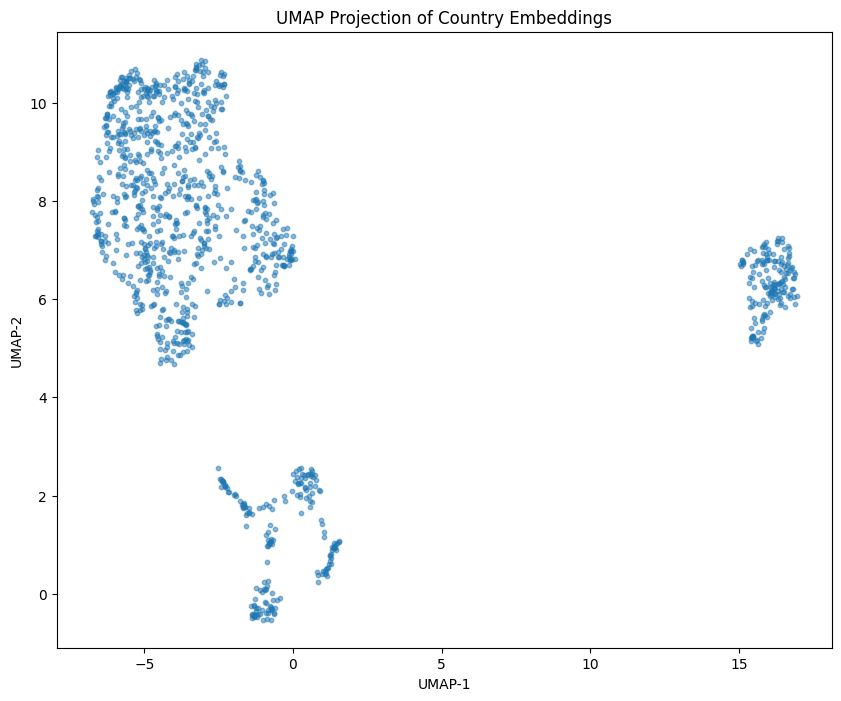

In [16]:
plt.figure(figsize=(10, 8))
plt.scatter(projected_dataset_embeddings[:, 0], projected_dataset_embeddings[:, 1], alpha=0.5, s=10)
plt.title("UMAP Projection of Country Embeddings")
plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")
plt.show()


### Step 11: Querying the vector store and projecting results
This step retrieves the top-k most similar text chunks to a user query by encoding the query and searching the FAISS vector store. The retrieved results and their embeddings are projected for further analysis or visualization.

In [17]:
def retrieve(query, k=5):
    """
    Retrieve the top k similar text chunks and their embeddings for a given query.
    """
    # Encode the query
    query_embedding = model.encode([query], convert_to_numpy=True)
    # Search the FAISS index
    distances, indices = index.search(query_embedding, k)
    print("Distances:", distances)
    print("Indices:", indices)
    print("token_split_texts len:", len(token_split_texts))
    valid_indices = [i for i in indices[0] if i < len(token_split_texts)]
    if not valid_indices:
        print("No valid indices found! Check your index and data alignment.")
        return [], [], []
    retrieved_texts = [token_split_texts[i] for i in valid_indices]
    retrieved_embeddings = np.array([chunk_embeddings[i] for i in valid_indices])
    return retrieved_texts, retrieved_embeddings, distances[0][:len(valid_indices)]


In [18]:
query = "Which country has the highest population in Asia?"
results, result_embeddings, distances = retrieve(query, k=3)
if results:
    print("Retrieved document preview:")
    print(results[0][:300])  # Preview of the first result
else:
    print("No results found for this query. Try a different query.")


Distances: [[17.776524 21.74155  22.07202 ]]
Indices: [[431 674 102]]
token_split_texts len: 1179
Retrieved document preview:
world's third-most-populous democracy and the world's largest Muslim-majority nation. It has had strong economic growth since overcoming the Asian financial crisis of the late 1990s. By the 2020s, it had the largest economy in Southeast Asia, and its economy ranked in the world's top 10 in terms of 


In [19]:
# Project the embeddings of the results
projected_result_embeddings = project_embeddings(result_embeddings, umap_transform)

# Also project the original query (for visualization, e.g. scatter plot with the query highlighted)
query_embedding = model.encode([query], convert_to_numpy=True)
project_original_query = project_embeddings(query_embedding, umap_transform)


Projecting Embeddings:   0%|          | 0/3 [00:00<?, ?it/s]C:\Users\Selin\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\Selin\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\Selin\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
Projecting Embeddings:   0%|          | 0/1 [00:00<?, ?it/s]C:\Users\Selin\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
Projecting E

### Step 12: Visualizing the Results

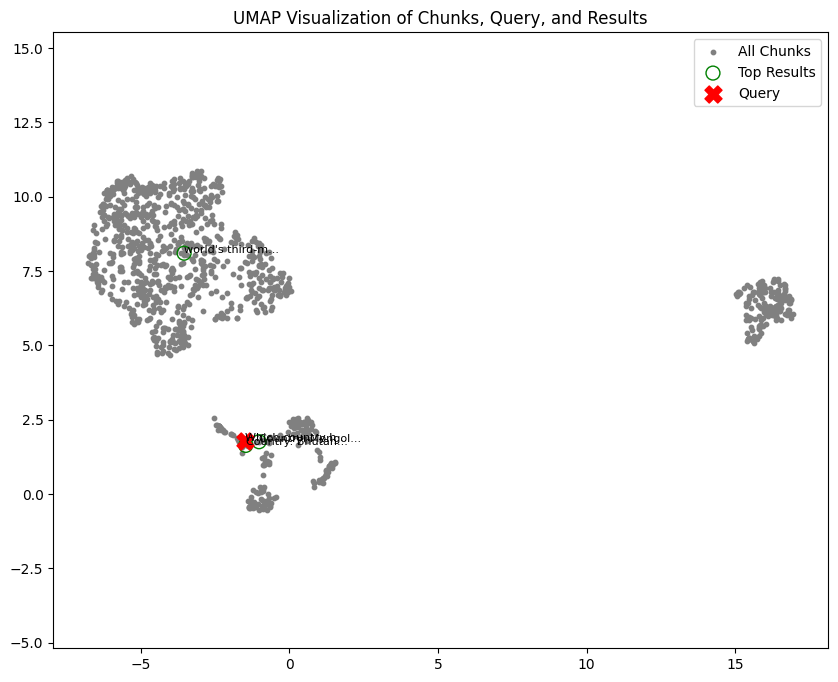

In [20]:
def shorten_text(text, max_length=15):
    """Shortens text to max_length and adds an ellipsis if shortened."""
    return (text[:max_length] + '...') if len(text) > max_length else text

plt.figure(figsize=(10, 8))

# Scatter plot for the full dataset
plt.scatter(
    projected_dataset_embeddings[:, 0], projected_dataset_embeddings[:, 1],
    s=10, color='gray', label='All Chunks'
)

# Scatter plot for the retrieved results
plt.scatter(
    projected_result_embeddings[:, 0], projected_result_embeddings[:, 1],
    s=100, facecolors='none', edgecolors='g', label='Top Results'
)

# Scatter plot for the original query
plt.scatter(
    project_original_query[:, 0], project_original_query[:, 1],
    s=150, marker='X', color='r', label='Query'
)

# Annotate the retrieved results
for i, text in enumerate(results):
    if i < len(projected_result_embeddings):
        plt.annotate(shorten_text(text), 
                     (projected_result_embeddings[i, 0], projected_result_embeddings[i, 1]),
                     fontsize=8)

# Annotate the query point
query_text = query  # or set a manual label if you want
plt.annotate(shorten_text(query_text), 
             (project_original_query[0, 0], project_original_query[0, 1]), fontsize=8)

plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP Visualization of Chunks, Query, and Results')
plt.legend()
plt.show()


### Step 13: Mapping Country Data to Hint Categories
In this step, we implement logic to map user-selected hint categories (geography, food, history, flag, etc.) to the corresponding data fields for each country. This mapping will serve as the basis for generating user hints in the GeoGuessr game.


In [21]:
def get_hint_candidates(country_row, hint_category):
    if hint_category == "geography":
        return [country_row['location'], country_row['area_comparative'], country_row['capital'], country_row['map_reference']]
    elif hint_category == "food":
        return [country_row['food1'], country_row['food2'], country_row['food3']]
    elif hint_category == "history":
        # Optional: Extrahiere Sätze mit Jahreszahlen aus background
        return extract_historical_facts(country_row['background'])
    elif hint_category == "flag":
        return [country_row['flag_url']]
    elif hint_category == "random":
        all_facts = [country_row[x] for x in country_row.index if isinstance(country_row[x], str) and country_row[x]]
        return random.sample(all_facts, 1)
    else:
        return ["No hint available."]


### Step 14: Query Expansion for User Hint Categories
This function expands a user category selection into a natural language prompt for the LLM, ensuring variety and guiding the model to use the correct data fields.


In [22]:
def expand_query(user_input):
    """
    Expands a user hint category into a tailored prompt for the LLM to generate varied, quiz-style hints.
    """
    user_input = user_input.strip().lower()
    if user_input in ["geography", "geo"]:
        return (
            "Create a new, interesting geography hint as a single sentence. "
            "Combine at least two of these: neighboring countries, capital city, population, area (with comparison), "
            "region, major cities, or a notable physical feature. Use different combinations for each new hint."
        )
    elif user_input in ["flag", "flag description"]:
        return (
            "Describe one special aspect of the national flag in a clear sentence. "
            "Mention main colors and one symbol. If possible, include the flag URL."
        )
    elif user_input in ["food", "cuisine"]:
        return (
            "State two key traditional dishes or food specialty in a natural sentence. "
            "Mention the food type, how it is eaten, or its importance in culture."
            
        )
    elif user_input in ["history"]:
        return (
            "Write two historical facts as two sentences, each time using a new detail. "
            "Choose from founding, independence, major wars/events, famous leaders, or other historical facts."
        )
    elif user_input in ["random"]:
        return (
            "Give a surprising or fun fact about the country: people, language, tradition, nature, or records."
        )
    else:
        return f"Give a short, quiz-style fact about the country related to: {user_input}"

# Example test
for cat in ["geography", "flag", "food", "history", "random"]:
    print(f"User Input: {cat}\nExpanded Query: {expand_query(cat)}\n")


User Input: geography
Expanded Query: Create a new, interesting geography hint as a single sentence. Combine at least two of these: neighboring countries, capital city, population, area (with comparison), region, major cities, or a notable physical feature. Use different combinations for each new hint.

User Input: flag
Expanded Query: Describe one special aspect of the national flag in a clear sentence. Mention main colors and one symbol. If possible, include the flag URL.

User Input: food
Expanded Query: State two key traditional dishes or food specialty in a natural sentence. Mention the food type, how it is eaten, or its importance in culture.

User Input: history
Expanded Query: Write two historical facts as two sentences, each time using a new detail. Choose from founding, independence, major wars/events, famous leaders, or other historical facts.

User Input: random
Expanded Query: Give a surprising or fun fact about the country: people, language, tradition, nature, or records.

### Step 15: Category-based Re-ranking of Retrieved Chunks
This step improves the relevance of the retrieved text chunks by re-ranking them according to category-specific keywords. Each chunk is scored based on how many keywords (from the selected hint type) appear in its content, ensuring that the top results are more aligned with the user's chosen category (e.g., "history", "food", etc.).


In [23]:
def rerank_chunks_by_category(chunks, hint_type, top_n=5):
    keywords_map = {
        "geography": ["border", "neighbor", "capital", "region", "area", "city", "mountain", "sea", "river"],
        "food": ["dish", "cuisine", "eat", "food", "meal", "specialty", "ingredient"],
        "flag": ["flag", "symbol", "color", "banner", "emblem"],
        "history": ["war", "independence", "colony", "leader", "founding", "republic", "revolution"],
        "random": [],
        
    }
    keywords = keywords_map.get(hint_type.lower(), [])
    ranked_chunks = sorted(
        chunks,
        key=lambda c: sum(1 for kw in keywords if kw in c.lower()),
        reverse=True
    )
    return ranked_chunks[:top_n]


### Step 16: Gemini LLM initialization and prompting
This step loads the environment variables (including the Google API key) and initializes the Gemini large language model (LLM) via LangChain. The model will later be used to generate hints and answers based on user queries in the game.

In [24]:
import os
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain.prompts import PromptTemplate

# Load .env file for environment variables
from dotenv import load_dotenv
load_dotenv()
GOOGLE_API_KEY = os.getenv("GOOGLE_API_KEY")

# Initialize the Gemini LLM (via LangChain)
model = ChatGoogleGenerativeAI(
    model="gemini-1.5-pro-latest",
    temperature=0.7,
    google_api_key=GOOGLE_API_KEY
)


### Step 17: Building the prompt template for the LLM
This step creates a structured prompt template that guides the language model to generate a relevant hint based on the selected country, category, details, and context. The template ensures the LLM always receives the required context for consistent, quiz-like outputs.

In [25]:
system_template = """
You are an AI quizmaster. Based on the following context about the country, generate a helpful hint for the quiz player.

Category: {category}
Details: {details}

Context:
{context}

Hint:
"""

# Build the PromptTemplate
question_answering_prompt = PromptTemplate(
    template=system_template,
    input_variables=["country", "category", "details", "context"]
)


### Step 18: Generate first hint 
This step demonstrates how to generate a hint for a quiz game using retrieval-augmented generation (RAG). A query is created using the country and category, relevant context is retrieved from the vector store, and the best matching chunk is selected and provided to the language model (LLM) to generate a targeted hint.

In [26]:
from sentence_transformers import SentenceTransformer
embedding_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")


country = "Japan"
category = "history"

# Query Expansion
details = expand_query(category)

# Retrieval (embeddings):
llm_query = f"{country} {category}"
query_embedding = embedding_model.encode(llm_query)
k = 5
D, I = index.search(np.array([query_embedding]), k)
retrieved_chunks = [token_split_texts[idx] for idx in I[0]]

# Re-ranking
ranked_chunks = rerank_chunks_by_category(retrieved_chunks, category, top_n=3)

# Provide the best context chunk for the prompt
context = ranked_chunks[0] if ranked_chunks else ""

prompt = question_answering_prompt.format(
    country=country,
    category=category,
    details=details,
    context=context
)

# Generate LLM response (hint)
response = model.invoke(prompt)
print(response.content)


Think about the major conflicts that shaped 20th-century China, particularly those involving Japan and the internal struggle for power.


### Step 19: Involve user interaction
In this step, the code enables interactive gameplay by involving the user in the game loop. The user first selects a continent, then a random country is chosen from that continent. The user can select a hint category (e.g., geography, history, flag, food, or random), which influences the hint generation. The pipeline then runs query expansion, retrieves relevant document chunks using embeddings and the FAISS index, re-ranks the chunks based on the selected category, and finally generates a prompt for the Gemini LLM, which returns a context-aware hint.

In [27]:
import random
from sentence_transformers import SentenceTransformer
embedding_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

# Show continents
available_continents = sorted(set(countries_df['map_reference'].dropna()))
print("Available continents:", ", ".join(available_continents))
selected_continent = input("Select a continent: ").strip()

# Filter countries in continent and choose random country
countries_in_continent = countries_df[countries_df['map_reference'] == selected_continent]
chosen_row = countries_in_continent.sample(1).iloc[0]
country_name = chosen_row['country']
print("(System: The country has been chosen.)")

# Select category
hint_types = ["geography", "history", "flag", "food", "random"]
print("Hint types:", ", ".join(hint_types))
selected_hint_type = input("Select a hint category: ").strip().lower()

# Query expansion and generate details
details = expand_query(selected_hint_type)

# Embedding for FAISS index search
llm_query = f"{country_name} {selected_hint_type}"
query_embedding = embedding_model.encode(llm_query)  # Attention: embedding_model is SentenceTransformer, NOT ChatGoogleGenerativeAI!
k = 5
D, I = index.search(np.array([query_embedding]), k)
retrieved_chunks = [token_split_texts[idx] for idx in I[0]]

# Rerank best chunks by category
ranked_chunks = rerank_chunks_by_category(retrieved_chunks, selected_hint_type, top_n=3)

# Build prompt template for Gemini
context = "\n".join(ranked_chunks)
prompt = question_answering_prompt.format(
    country=country_name,
    category=selected_hint_type,
    details=details,
    context=context
)

# Get LLM answer
response = model.invoke(prompt)
print("\n🤖 Gemini Hint Output:\n")
print(response.content)


Available continents: Africa, Arctic Region, Asia, AsiaEurope, Central America and the Caribbean, Europe, Middle East, North America, Oceania, South America, Southeast Asia, nan
(System: The country has been chosen.)
Hint types: geography, history, flag, food, random

🤖 Gemini Hint Output:

Think of cheesy and potato-based dishes enjoyed in the mountains.


### Step 20: Initialize and Play Interactive Hints Game Mode
This step implements the interactive game mode where players try to guess a randomly selected country from a chosen continent. The game provides up to 5 AI-generated hints per round, and the player can guess at any time. Each round ensures no duplicate hints per category, and the game can be replayed as often as desired.

In [28]:
import random
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

def play_geoguessr():
    while True:
        # STEP 1: Select continent
        available_continents = sorted(set(countries_df['map_reference'].dropna()))
        print("\nAvailable continents:", ", ".join(available_continents))
        selected_continent = input("Select a continent: ").strip()

        # STEP 2: Select random country
        countries_in_continent = countries_df[countries_df['map_reference'] == selected_continent]
        if countries_in_continent.empty:
            print("No country found. Please try again.")
            continue
        chosen_row = countries_in_continent.sample(1).iloc[0]
        country_name = chosen_row['country']
        print("(System: The country has been chosen.)")

        # Init game round
        used_hints = []    # List of tuples: (category, text)
        used_categories = []   # To avoid repeating categories

        for hint_nr in range(1, 6):   # Up to 5 hints per round
            print(f"\nHint {hint_nr}:")

            # STEP 3: Select hint category
            hint_types = ["geography", "history", "flag", "food", "random"]
            print("Hint types:", ", ".join(hint_types))
            selected_hint_type = input("Choose a category for the next hint: ").strip().lower()

            # STEP 4: Query expansion
            details = expand_query(selected_hint_type)

            # STEP 5: Embedding & Retrieval
            llm_query = f"{country_name} {selected_hint_type}"
            query_embedding = embedding_model.encode(llm_query)
            k = 5
            D, I = index.search(np.array([query_embedding]), k)
            retrieved_chunks = [token_split_texts[idx] for idx in I[0]]

            # STEP 6: Reranking
            ranked_chunks = rerank_chunks_by_category(retrieved_chunks, selected_hint_type, top_n=3)

            # Prevent duplicate hints for the same category
            filtered_chunks = [c for c in ranked_chunks if (selected_hint_type, c) not in used_hints]
            if not filtered_chunks:
                print("No new hints in this category. Please choose another category!")
                continue

            hint_chunk = filtered_chunks[0]
            used_hints.append((selected_hint_type, hint_chunk))
            used_categories.append(selected_hint_type)

            # STEP 7: Build prompt template for Gemini
            context = hint_chunk  # Only the current hint is used as context
            prompt = question_answering_prompt.format(
                country=country_name,
                category=selected_hint_type,
                details=details,
                context=context
            )

            # STEP 8: Get LLM response
            response = model.invoke(prompt)
            print("\n🤖 Gemini Hint Output:\n")
            print(response.content)

            # User decision: Guess or get another hint
            next_action = input("\nDo you want to guess ('guess') or get another hint ('hint')? ").strip().lower()
            if next_action == 'guess':
                guess = input("Your guess: ").strip()
                if guess.lower() == country_name.lower():
                    print("🎉 Correct! The country was:", country_name)
                    break
                else:
                    print("❌ Incorrect! You can try again.")
            # If 'hint', the loop continues (up to 5 hints)
            if hint_nr == 5:
                print(f"\n🔔 The maximum of 5 hints has been reached. The country was: {country_name}")

        # After each round
        play_again = input("\nPlay another round? (yes/no): ").strip().lower()
        if play_again != 'yes':
            print("Thanks for playing! 👋")
            break

# Start Game
play_geoguessr()



Available continents: Africa, Arctic Region, Asia, AsiaEurope, Central America and the Caribbean, Europe, Middle East, North America, Oceania, South America, Southeast Asia, nan
(System: The country has been chosen.)

Hint 1:
Hint types: geography, history, flag, food, random

🤖 Gemini Hint Output:

Think hearty and comforting dishes, one a savory stew and the other a simple bread often enjoyed with meals.  One is a staple of Irish cuisine, particularly in colder months, while the other is a quick bread that was historically a key part of the Irish diet.

Hint 2:
Hint types: geography, history, flag, food, random

🤖 Gemini Hint Output:

Think about unusual driving laws or customs.  Which side of the road do they drive on in the UK?

Hint 3:
Hint types: geography, history, flag, food, random

🤖 Gemini Hint Output:

Slightly smaller than the US state of Oregon, the United Kingdom, with its capital London, is located in Western Europe and shares a land border with the Republic of Ireland

### Step 21:  Interactive country guessing based on capitals
In this step, we implement the "Capitals Game," an interactive quiz where players are prompted with the name of a capital city and must guess the corresponding country. The game supports continent selection, keeps track of the user's score and mistakes, and handles minor typos or variations using fuzzy string matching. The round continues until the player makes too many mistakes or all countries in a continent have been played. This step demonstrates how to combine LLM-based prompts and classic Python logic to create an engaging, educational game experience.

In [29]:
import random
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain.prompts import PromptTemplate

import difflib

# LLM Setup
model = ChatGoogleGenerativeAI(model="gemini-1.5-pro-latest", temperature=0.3, google_api_key=GOOGLE_API_KEY)

# Prompt Template for Fuzzy Matching
eval_template = """
Check if the user's guess for the COUNTRY is correct, given the CAPITAL.
Capital: Tokyo
User guess: Japan

- Accept typos, alternative country names, and clear correct answers.
- Output only "correct" or "incorrect" (no explanation).
"""
eval_prompt = PromptTemplate(
    template=eval_template,
    input_variables=["country", "capital", "guess"]
)



def is_guess_close_capital(guess, correct_capital, cutoff=0.8):
    # Lowercase and strip for comparison
    guess = guess.strip().lower()
    correct_capital = correct_capital.strip().lower()
    # Direct match
    if guess == correct_capital:
        return True
    # Fuzzy match (using difflib)
    matches = difflib.get_close_matches(guess, [correct_capital], n=1, cutoff=cutoff)
    return bool(matches)


def play_capitals_game_with_continent(countries_df, model, eval_prompt):
    print("\n=== Capitals Game: Guess the Country from the Capital! ===\n")
    highscore = 0
    max_errors = 3
    errors = 0
    already_played = set()

    # Select Continent
    available_continents = sorted(set(countries_df['map_reference'].dropna()))
    print("Available continents:", ", ".join(available_continents))
    selected_continent = input("Select a continent: ").strip()

    countries_in_continent = countries_df[countries_df['map_reference'] == selected_continent]
    countries_capitals = countries_in_continent[['country', 'capital']].dropna().values.tolist()

    if not countries_capitals:
        print("No countries found for this continent. Exiting.")
        return

    # Step 2: Main Game Loop
    while errors < max_errors:
        # Pick a random country/capital not played yet
        available_choices = [x for x in countries_capitals if x[0] not in already_played]
        if not available_choices:
            print("No more countries left in this continent. Game over!")
            break

        country, capital = random.choice(available_choices)
        already_played.add(country)

        print(f"\nCapital: {capital}")
        guess = input("Which country does this capital belong to? (Type your answer, or press Enter to skip): ").strip()

        # If user just presses Enter, count as incorrect
        if not guess:
            errors += 1
            print(f"❌ Incorrect! You entered: [empty] | Correct answer: {country}")
            print(f"Score: {highscore} | Errors: {errors}/{max_errors}")
            continue

        if is_guess_close_capital(guess, country):
            highscore += 1
            print(f"✅ Correct! Your answer: {guess} | Country: {country}")
        else:
            errors += 1
            print(f"❌ Incorrect! Your answer: {guess} | Correct answer: {country}")

        print(f"Score: {highscore} | Errors: {errors}/{max_errors}")

    print("\n--- GAME OVER ---")
    print(f"Your highscore: {highscore}")

    play_again = input("Do you want to play another round? (yes/no): ").strip().lower()
    if play_again == "yes":
        play_capitals_game_with_continent(countries_df, model, eval_prompt)
    else:
        print("Thanks for playing! 👋")

# Run capital game
play_capitals_game_with_continent(countries_df, model, eval_prompt)



=== Capitals Game: Guess the Country from the Capital! ===

Available continents: Africa, Arctic Region, Asia, AsiaEurope, Central America and the Caribbean, Europe, Middle East, North America, Oceania, South America, Southeast Asia, nan



Capital: Podgorica
❌ Incorrect! Your answer: ja | Correct answer: Montenegro
Score: 0 | Errors: 1/3

Capital: Tirana
❌ Incorrect! Your answer: Ay | Correct answer: Albania
Score: 0 | Errors: 2/3

Capital: Brussels
✅ Correct! Your answer: Belgium | Country: Belgium
Score: 1 | Errors: 2/3

Capital: Berlin
✅ Correct! Your answer: Germany | Country: Germany
Score: 2 | Errors: 2/3

Capital: Vienna
❌ Incorrect! Your answer: js | Correct answer: Austria
Score: 2 | Errors: 3/3

--- GAME OVER ---
Your highscore: 2
Thanks for playing! 👋


### Step 22:  Interactive flag guessing game
In this step, we implement an interactive "flag guessing" game mode. The user selects a continent, and the program filters all countries in that continent that have a valid flag image URL. A random country is selected in each round, and its flag is displayed (or the flag URL is shown if images are unavailable). The user then tries to guess the country based on the flag. The game gives feedback, tracks scores and errors, and allows replay.

This version includes typo-tolerant country matching to make the game more user-friendly.


In [30]:
import requests

def is_valid_image_url(url):
    try:
        r = requests.head(url, timeout=2)
        return r.status_code == 200 and 'image' in r.headers.get('content-type', '')
    except Exception:
        return False

# Filter countries BEFORE game starts
countries_with_valid_flag = countries_in_continent[
    countries_in_continent['flag_url'].apply(lambda url: is_valid_image_url(str(url)))
]
countries_flags = countries_with_valid_flag[['country', 'flag_url']].values.tolist()


In [31]:
import random
import difflib
from IPython.display import display, Image

def is_guess_close(guess, country):
    """Returns True if guess is very close (typo-tolerant), else False."""
    guess = guess.strip().lower()
    country = country.strip().lower()
    ratio = difflib.SequenceMatcher(None, guess, country).ratio()
    return ratio >= 0.85 

def play_flag_quiz_with_continent(countries_df, show_image=True):
    print("\n=== Flag Quiz: Guess the Country from the Flag! ===\n")
    highscore = 0
    max_errors = 3
    errors = 0
    already_played = set()

    # Select Continent
    available_continents = sorted(set(countries_df['map_reference'].dropna()))
    print("Available continents:", ", ".join(available_continents))
    selected_continent = input("Select a continent: ").strip()

    # Only countries with valid flag URL
    countries_in_continent = countries_df[
        (countries_df['map_reference'] == selected_continent) &
        (countries_df['flag_url'].notnull()) &
        (countries_df['flag_url'].str.strip() != "")
    ]
    countries_flags = countries_in_continent[['country', 'flag_url']].values.tolist()

    if not countries_flags:
        print("No countries with flags found for this continent. Exiting.")
        return

    # Main Game Loop
    while errors < max_errors:
        available_choices = [x for x in countries_flags if x[0] not in already_played]
        if not available_choices:
            print("No more countries left in this continent. Game over!")
            break

        country, flag_url = random.choice(available_choices)
        already_played.add(country)

        print(f"\nFlag of this country:")
        if show_image:
            try:
                display(Image(url=flag_url))
            except Exception:
                print(flag_url)
        else:
            print(flag_url)

        guess = input("Which country does this flag belong to? (Type your answer, or press Enter to skip): ").strip()

        # Always show the user input in feedback
        if not guess:
            errors += 1
            print(f"❌ Incorrect! You entered: [empty] | Correct answer: {country}")
            print(f"Score: {highscore} | Errors: {errors}/{max_errors}")
            continue

        if is_guess_close(guess, country):
            highscore += 1
            print(f"✅ Correct! Your answer: {guess} | Country: {country}")
        else:
            errors += 1
            print(f"❌ Incorrect! Your answer: {guess} | Correct answer: {country}")

        print(f"Score: {highscore} | Errors: {errors}/{max_errors}")

    print("\n--- GAME OVER ---")
    print(f"Your highscore: {highscore}")

    play_again = input("Do you want to play another round? (yes/no): ").strip().lower()
    if play_again == "yes":
        play_flag_quiz_with_continent(countries_df, show_image)
    else:
        print("Thanks for playing! 👋")

# Run flag game
play_flag_quiz_with_continent(countries_df, show_image=True)



=== Flag Quiz: Guess the Country from the Flag! ===

Available continents: Africa, Arctic Region, Asia, AsiaEurope, Central America and the Caribbean, Europe, Middle East, North America, Oceania, South America, Southeast Asia, nan

Flag of this country:


✅ Correct! Your answer: Germany | Country: Germany
Score: 1 | Errors: 0/3

Flag of this country:


✅ Correct! Your answer: Greece | Country: Greece
Score: 2 | Errors: 0/3

Flag of this country:


❌ Incorrect! Your answer: dd | Correct answer: Slovenia
Score: 2 | Errors: 1/3

Flag of this country:


❌ Incorrect! Your answer: d | Correct answer: Norway
Score: 2 | Errors: 2/3

Flag of this country:


❌ Incorrect! Your answer: s | Correct answer: Netherlands
Score: 2 | Errors: 3/3

--- GAME OVER ---
Your highscore: 2
Thanks for playing! 👋


### Step 23:  Integrate and launch the complete GeoGuesser game
In this step, we bring together all three games—Hints Game, Flag Quiz, and Capital Quiz—into a single interactive menu. Players can switch between the games, see their personal highscores (stored in memory), and exit or restart as they wish. Each game provides a user-friendly way to quit back to the menu at any point.



In [32]:
# Initialize highscores
highscores = {
    "Hints Game": 0,
    "Flag Quiz": 0,
    "Capital Quiz": 0,
}

def main_menu():
    while True:
        print("\n=== GeoGuessr Main Menu ===")
        print("1. Hints Game (Highscore: {})".format(highscores["Hints Game"]))
        print("2. Flag Quiz (Highscore: {})".format(highscores["Flag Quiz"]))
        print("3. Capital Quiz (Highscore: {})".format(highscores["Capital Quiz"]))
        print("4. Exit")
        choice = input("Choose a game (1-4): ").strip()
        
        if choice == "1":
            score = play_geoguessr()
            if score > highscores["Hints Game"]:
                highscores["Hints Game"] = score
        elif choice == "2":
            score = play_flag_quiz_with_continent(countries_df, show_image=True)
            if score > highscores["Flag Quiz"]:
                highscores["Flag Quiz"] = score
        elif choice == "3":
            score = play_capitals_game_with_continent(countries_df, model, eval_prompt)
            if score > highscores["Capital Quiz"]:
                highscores["Capital Quiz"] = score
        elif choice == "4":
            print("Bye! 👋")
            break
        else:
            print("Invalid input. Try again.")


# Game function (Hints Game) with menu return option

def play_geoguessr():
    highscore = 0
    while True:
        # Select continent
        available_continents = sorted(set(countries_df['map_reference'].dropna()))
        print("\nAvailable continents:", ", ".join(available_continents))
        selected_continent = input("Select a continent (or type 'exit'): ").strip()
        if selected_continent.lower() == "exit":
            print("Return to main menu!")
            break

        countries_in_continent = countries_df[countries_df['map_reference'] == selected_continent]
        if countries_in_continent.empty:
            print("No countries found. Please try again.")
            continue
        chosen_row = countries_in_continent.sample(1).iloc[0]
        country_name = chosen_row['country']
        print("(System: The country has been chosen.)")

        used_hints = []
        used_categories = []

        for hint_nr in range(1, 6):  # Max 5 hints
            print(f"\nHint {hint_nr}:")
            hint_types = ["geography", "history", "flag", "food", "random"]
            print("Hint types:", ", ".join(hint_types))
            selected_hint_type = input("Choose a category for the next hint (or 'exit'): ").strip().lower()
            if selected_hint_type == "exit":
                print("Return to main menu!")
                return highscore 

            # Query-Expansion
            details = expand_query(selected_hint_type)

            # Embedding & Retrieval
            llm_query = f"{country_name} {selected_hint_type}"
            query_embedding = embedding_model.encode(llm_query)
            k = 5
            D, I = index.search(np.array([query_embedding]), k)
            retrieved_chunks = [token_split_texts[idx] for idx in I[0]]

            # Re-ranking
            ranked_chunks = rerank_chunks_by_category(retrieved_chunks, selected_hint_type, top_n=3)

            filtered_chunks = [c for c in ranked_chunks if (selected_hint_type, c) not in used_hints]
            if not filtered_chunks:
                print("No new hints left in this category. Choose another category!")
                continue

            hint_chunk = filtered_chunks[0]
            used_hints.append((selected_hint_type, hint_chunk))
            used_categories.append(selected_hint_type)

            # Prompt template for Gemini
            context = hint_chunk
            prompt = question_answering_prompt.format(
                country=country_name,
                category=selected_hint_type,
                details=details,
                context=context
            )

            # Get LLM response
            response = model.invoke(prompt)
            print("\n🤖 Gemini Hint Output:\n")
            print(response.content)

            # User-Entscheidung: Guess oder weiterer Hint
            next_action = input("\nDo you want to guess ('guess'), get another hint ('hint'), or exit to menu ('exit')? ").strip().lower()
            if next_action == 'exit':
                print("Return to main menu!")
                return highscore
            if next_action == 'guess':
                guess = input("Your guess (or 'exit'): ").strip()
                if guess.lower() == "exit":
                    print("Return to main menu!")
                    return highscore
                if guess.lower() == country_name.lower():
                    print("Correct! The country was:", country_name)
                    highscore += 1 
                    break
                else:
                    print("Incorrect! You can try again.")

            if hint_nr == 5:
                print(f"\nMaximum 5 hints reached. The country was: {country_name}")

      
        play_again = input("\nPlay another round? (yes/no/exit): ").strip().lower()
        if play_again in ['no', 'exit']:
            print("Thanks for playing!")
            break
    return highscore  # Nach Ende alle Runden


# Play flag quiz

import random
import difflib
from IPython.display import display, Image  

def is_guess_close(guess, country):
    """Returns True if guess is very close (typo-tolerant), else False."""
    guess = guess.strip().lower()
    country = country.strip().lower()
    ratio = difflib.SequenceMatcher(None, guess, country).ratio()
    return ratio >= 0.85

def play_flag_quiz_with_continent(countries_df, show_image=True):
    print("\n=== Flag Quiz: Guess the Country from the Flag! ===\n")
    highscore = 0
    max_errors = 3
    errors = 0
    already_played = set()

    # Select Continent
    available_continents = sorted(set(countries_df['map_reference'].dropna()))
    print("Available continents:", ", ".join(available_continents))
    selected_continent = input("Select a continent (or type 'exit'): ").strip()
    if selected_continent.lower() == "exit":
        print("Zurück zum Hauptmenü!")
        return highscore

    # --- Nur Länder mit Flagge ---
    countries_in_continent = countries_df[
        (countries_df['map_reference'] == selected_continent) &
        (countries_df['flag_url'].notnull()) &
        (countries_df['flag_url'].str.strip() != "")
    ]
    countries_flags = countries_in_continent[['country', 'flag_url']].values.tolist()

    if not countries_flags:
        print("No countries with flags found for this continent. Exiting.")
        return highscore

    # --- Step 2: Main Game Loop ---
    while errors < max_errors:
        available_choices = [x for x in countries_flags if x[0] not in already_played]
        if not available_choices:
            print("No more countries left in this continent. Game over!")
            break

        country, flag_url = random.choice(available_choices)
        already_played.add(country)

        print(f"\nFlag of this country:")
        if show_image:
            try:
                display(Image(url=flag_url))
            except Exception:
                print(flag_url)
        else:
            print(flag_url)

        guess = input("Which country does this flag belong to? (type answer, 'exit' to menu, Enter to skip): ").strip()
        if guess.lower() == "exit":
            print("Zurück zum Hauptmenü!")
            return highscore

        if not guess:
            errors += 1
            print(f"Incorrect! You entered: [empty] | Correct answer: {country}")
            print(f"Score: {highscore} | Errors: {errors}/{max_errors}")
            continue

        if is_guess_close(guess, country):
            highscore += 1
            print(f"Correct! Your answer: {guess} | Country: {country}")
        else:
            errors += 1
            print(f"Incorrect! Your answer: {guess} | Correct answer: {country}")

        print(f"Score: {highscore} | Errors: {errors}/{max_errors}")

    print("\n--- GAME OVER ---")
    print(f"Your highscore: {highscore}")

    while True:
        play_again = input("Do you want to play another round? (yes/no/exit): ").strip().lower()
        if play_again == "exit":
            print("Zurück zum Hauptmenü!")
            return highscore
        if play_again == "yes":
            return play_flag_quiz_with_continent(countries_df, show_image)
        if play_again == "no":
            print("Thanks for playing!")
            break
    return highscore


# Play capital game

def is_guess_close_capital(guess, country):
    """Returns True if guess is very close (typo-tolerant), else False."""
    guess = guess.strip().lower()
    country = country.strip().lower()
    ratio = difflib.SequenceMatcher(None, guess, country).ratio()
    return ratio >= 0.85 



def play_capitals_game_with_continent(countries_df, model, eval_prompt):
    print("\n=== Capitals Game: Guess the Country from the Capital! ===\n")
    highscore = 0
    max_errors = 3
    errors = 0
    already_played = set()

    # Select Continent ---
    available_continents = sorted(set(countries_df['map_reference'].dropna()))
    print("Available continents:", ", ".join(available_continents))
    selected_continent = input("Select a continent (or type 'exit'): ").strip()
    if selected_continent.lower() == "exit":
        print("Zurück zum Hauptmenü!")
        return highscore

    countries_in_continent = countries_df[countries_df['map_reference'] == selected_continent]
    countries_capitals = countries_in_continent[['country', 'capital']].dropna().values.tolist()

    if not countries_capitals:
        print("No countries found for this continent. Exiting.")
        return highscore

    # Main Game Loop ---
    while errors < max_errors:
        # Pick a random country/capital not played yet
        available_choices = [x for x in countries_capitals if x[0] not in already_played]
        if not available_choices:
            print("No more countries left in this continent. Game over!")
            break

        country, capital = random.choice(available_choices)
        already_played.add(country)

        print(f"\nCapital: {capital}")
        guess = input("Which country does this capital belong to? (answer, Enter=skip, 'exit'=Menü): ").strip()
        if guess.lower() == "exit":
            print("Zurück zum Hauptmenü!")
            return highscore

        # If user just presses Enter, count as incorrect
        if not guess:
            errors += 1
            print(f"Incorrect! The correct answer was: {country}")
            print(f"Score: {highscore} | Errors: {errors}/{max_errors}")
            continue

        # LLM evaluation
        eval_input = eval_prompt.format(country=country, capital=capital, guess=guess)
        response = model.invoke(eval_input)
        decision = response.content.strip().lower()

        if "correct" in decision:
            highscore += 1
            print("Correct!")
        else:
            errors += 1
            print(f"Incorrect! The correct answer was: {country}")

        print(f"Score: {highscore} | Errors: {errors}/{max_errors}")

    print("\n--- GAME OVER ---")
    print(f"Your highscore: {highscore}")

    # User will always be able to exit to menu here:
    while True:
        play_again = input("Do you want to play another round? (yes/no/exit): ").strip().lower()
        if play_again == "exit":
            print("Zurück zum Hauptmenü!")
            return highscore
        if play_again == "yes":
            return play_capitals_game_with_continent(countries_df, model, eval_prompt)
        if play_again == "no":
            print("Thanks for playing! 👋")
            break
    return highscore

# --- Menü-Call: score = play_capitals_game_with_continent(countries_df, model, eval_prompt)


# Main-Loop starten
main_menu()



=== GeoGuessr Main Menu ===
1. Hints Game (Highscore: 0)
2. Flag Quiz (Highscore: 0)
3. Capital Quiz (Highscore: 0)
4. Exit



=== Flag Quiz: Guess the Country from the Flag! ===

Available continents: Africa, Arctic Region, Asia, AsiaEurope, Central America and the Caribbean, Europe, Middle East, North America, Oceania, South America, Southeast Asia, nan

Flag of this country:


Incorrect! You entered: [empty] | Correct answer: Liechtenstein
Score: 0 | Errors: 1/3

Flag of this country:


Correct! Your answer: Germany | Country: Germany
Score: 1 | Errors: 1/3

Flag of this country:


Incorrect! You entered: [empty] | Correct answer: Lithuania
Score: 1 | Errors: 2/3

Flag of this country:


Incorrect! You entered: [empty] | Correct answer: San Marino
Score: 1 | Errors: 3/3

--- GAME OVER ---
Your highscore: 1
Zurück zum Hauptmenü!

=== GeoGuessr Main Menu ===
1. Hints Game (Highscore: 0)
2. Flag Quiz (Highscore: 1)
3. Capital Quiz (Highscore: 0)
4. Exit
Bye! 👋


### Step 24: Gradio Web App Integration for Hints Game
This step transforms the Hints Game into an interactive web app using Gradio. Users can select a continent, choose a hint category, get AI-generated hints, and submit their guesses—all through a clean browser interface. Game state and feedback are managed in real-time, making the experience user-friendly and accessible without coding.

Key Features:

- Dropdown menus for continent and category selection
- Buttons to start a new game and get hints
- Text input for answers with instant feedback
- Live highscore and status updates

In [33]:
# Gradio Interface for the Hints Game
import gradio as gr

# Functions for the Gradio interface
def get_continents():
    return sorted(set(countries_df['map_reference'].dropna()))

def start_new_game(selected_continent):
    countries_in_continent = countries_df[countries_df['map_reference'] == selected_continent]
    if countries_in_continent.empty:
        return (
            gr.update(choices=get_continents(), value=None),
            gr.update(choices=[], value=None),
            '', '', '', '', [], [], 1, 0, 'No countries found. Please select another continent.'
        )
    chosen_row = countries_in_continent.sample(1).iloc[0]
    country_name = chosen_row['country']
    hint_types = ['geography', 'history', 'flag', 'food', 'random']
    return (
        gr.update(choices=get_continents(), value=selected_continent),
        gr.update(choices=hint_types, value=None),
        country_name, '', '', '', [], [], 1, 0, f'New game started! Country selected. Please choose a hint category.'
    )

def get_hint(country_name, selected_hint_type, used_hints, used_categories, hint_nr):
    if not country_name or not selected_hint_type:
        return '', used_hints, used_categories, hint_nr, 'Please select a country and a hint category first.'
    details = expand_query(selected_hint_type)
    llm_query = f'{country_name} {selected_hint_type}'
    query_embedding = embedding_model.encode(llm_query)
    k = 5
    D, I = index.search(np.array([query_embedding]), k)
    retrieved_chunks = [token_split_texts[idx] for idx in I[0]]
    ranked_chunks = rerank_chunks_by_category(retrieved_chunks, selected_hint_type, top_n=3)
    filtered_chunks = [c for c in ranked_chunks if (selected_hint_type, c) not in used_hints]
    if not filtered_chunks:
        return '', used_hints, used_categories, hint_nr, 'No new hints available in this category. Please choose another category!'
    hint_chunk = filtered_chunks[0]
    used_hints.append((selected_hint_type, hint_chunk))
    used_categories.append(selected_hint_type)
    context = hint_chunk
    prompt = question_answering_prompt.format(
        country=country_name,
        category=selected_hint_type,
        details=details,
        context=context
    )
    response = model.invoke(prompt)
    return response.content, used_hints, used_categories, hint_nr+1, f'Hint {hint_nr}: Kategorie {selected_hint_type}'

def check_guess(user_guess, country_name, highscore):
    if not user_guess or not country_name:
        return highscore, 'Please enter a guess.'
    if user_guess.strip().lower() == country_name.strip().lower():
        highscore += 1
        return highscore, f'Correct! The country was: {country_name}'
    else:
        return highscore, f'Wrong! The country was: {country_name}'

with gr.Blocks() as demo:
    gr.Markdown('# 🌍 GeoGuesser RAG – Hints Game')
    with gr.Row():
        continent_dropdown = gr.Dropdown(label='Select Continent', choices=get_continents())
        hint_type_dropdown = gr.Dropdown(label='Hint Category', choices=[])
    country_name_box = gr.Textbox(label='(Hidden) Country Name', visible=False)
    used_hints_state = gr.State([])
    used_categories_state = gr.State([])
    hint_nr_state = gr.State(1)
    highscore_state = gr.State(0)
    gr.Markdown('---')
    hint_output = gr.Markdown(label='Current Hint')
    user_guess_box = gr.Textbox(label='Your Guess', placeholder='Enter country...')
    feedback_box = gr.Markdown(label='Feedback')
    status_box = gr.Markdown(label='Status')

    # Start new game
    start_btn = gr.Button('Start New Game')
    start_btn.click(
        fn=start_new_game,
        inputs=[continent_dropdown],
        outputs=[
            continent_dropdown, hint_type_dropdown, country_name_box,
            hint_output, user_guess_box, feedback_box,
            used_hints_state, used_categories_state, hint_nr_state, highscore_state, status_box
        ]
    )

    # Get next hint
    get_hint_btn = gr.Button('Show next hint')
    get_hint_btn.click(
        fn=get_hint,
        inputs=[country_name_box, hint_type_dropdown, used_hints_state, used_categories_state, hint_nr_state],
        outputs=[hint_output, used_hints_state, used_categories_state, hint_nr_state, status_box]
    )

    # Submit guess
    guess_btn = gr.Button('Submit guess')
    guess_btn.click(
        fn=check_guess,
        inputs=[user_guess_box, country_name_box, highscore_state],
        outputs=[highscore_state, feedback_box]
    )

    gr.Markdown('''
     **Instructions:**  
    1. Select a continent and start a new game.  
    2. Choose a hint category and let the system provide hints.  
    3. Submit your guess!  
    ''')

    gr.Markdown('---')

demo.launch()

* Running on local URL:  http://127.0.0.1:7864

To create a public link, set `share=True` in `launch()`.


### Step 25: Unified Gradio App – Multi-Game Tabs
This step extends the previous Gradio interface by combining all three games—Hints Game, Flag Quiz, and Capital Quiz—into a single web app with separate tabs. Players can switch between different game types instantly, with each game maintaining its own state and highscore during the session. The UI now supports images for flags and structured input for capitals, making the experience more versatile and seamless.

In [34]:
import gradio as gr
import random

# Functions for the menu
def get_continents():
    return sorted(set(countries_df['map_reference'].dropna()))

# Hints Game
def hints_start(continent):
    countries_in_continent = countries_df[countries_df['map_reference'] == continent]
    if countries_in_continent.empty:
        return '', '', '', [], [], 1, 0, 'No country found. Please select another continent.'
    chosen_row = countries_in_continent.sample(1).iloc[0]
    country_name = chosen_row['country']
    return country_name, '', '', [], [], 1, 0, 'New game started! Country selected. Choose a hint category.'

def hints_get_hint(country_name, hint_type, used_hints, used_categories, hint_nr):
    if not country_name or not hint_type:
        return '', used_hints, used_categories, hint_nr, 'Please select a country and a hint category first.'
    details = expand_query(hint_type)
    llm_query = f'{country_name} {hint_type}'
    query_embedding = embedding_model.encode(llm_query)
    k = 5
    D, I = index.search(np.array([query_embedding]), k)
    retrieved_chunks = [token_split_texts[idx] for idx in I[0]]
    ranked_chunks = rerank_chunks_by_category(retrieved_chunks, hint_type, top_n=3)
    filtered_chunks = [c for c in ranked_chunks if (hint_type, c) not in used_hints]
    if not filtered_chunks:
        return '', used_hints, used_categories, hint_nr, 'No new hints left in this category. Choose another category!'
    hint_chunk = filtered_chunks[0]
    used_hints.append((hint_type, hint_chunk))
    used_categories.append(hint_type)
    context = hint_chunk
    prompt = question_answering_prompt.format(
        country=country_name,
        category=hint_type,
        details=details,
        context=context
    )
    response = model.invoke(prompt)
    return response.content, used_hints, used_categories, hint_nr+1, f'Hint {hint_nr}: Category {hint_type}'

def hints_check_guess(user_guess, country_name, highscore):
    if not user_guess or not country_name:
        return highscore, 'Please enter your guess.'
    if user_guess.strip().lower() == country_name.strip().lower():
        highscore += 1
        return highscore, f'Correct! The country was: {country_name}'
    else:
        return highscore, f'Wrong! The country was: {country_name}'

# Flag Quiz
def flag_start(continent):
    countries_in_continent = countries_df[
        (countries_df['map_reference'] == continent) &
        (countries_df['flag_url'].notnull()) &
        (countries_df['flag_url'].str.strip() != "")
    ]
    if countries_in_continent.empty:
        return '', '', '', 0, 0, 'No country with flag found. Please select another continent.'
    country, flag_url = random.choice(countries_in_continent[['country', 'flag_url']].values.tolist())
    return country, flag_url, '', 0, 0, 'Flag selected!'

def flag_check_guess(user_guess, country, score, errors):
    if not user_guess:
        errors += 1
        return score, errors, f'Wrong! No input. The country was: {country}'
    if is_guess_close(user_guess, country):
        score += 1
        return score, errors, f'Correct! The country was: {country}'
    else:
        errors += 1
        return score, errors, f'Wrong! The country was: {country}'

# Capitals Quiz
def capitals_start(continent):
    countries_in_continent = countries_df[countries_df['map_reference'] == continent]
    countries_capitals = countries_in_continent[['country', 'capital']].dropna().values.tolist()
    if not countries_capitals:
        return '', '', '', 0, 0, 'No country with capital found. Please select another continent.'
    country, capital = random.choice(countries_capitals)
    return country, capital, '', 0, 0, 'Capital selected!'

def capitals_check_guess(user_guess, country, capital, score, errors):
    if not user_guess:
        errors += 1
        return score, errors, f'Wrong! No input. The capital of {country} was: {capital}'
    if is_guess_close_capital(user_guess, capital):
        score += 1
        highscores["Capital Quiz"] = max(score, highscores["Capital Quiz"])
        return score, errors, f'Correct! The capital of {country} was: {capital}'
    else:
        errors += 1
        return score, errors, f'Wrong! Your guess: {user_guess} | The capital of {country} was: {capital}'

# --- Gradio Interface ---
with gr.Blocks() as demo:
    gr.Markdown("# 🌍 GeoGuesser RAG – All Games")
    with gr.Tab("Hints Game"):
        with gr.Row():
            hints_continent = gr.Dropdown(label='Select continent', choices=get_continents())
            hints_hint_type = gr.Dropdown(label='Hint category', choices=['geography', 'history', 'flag', 'food', 'random'])
        hints_country = gr.Textbox(visible=False)
        hints_hint = gr.Markdown()
        hints_user_guess = gr.Textbox(label='Your guess')
        hints_feedback = gr.Markdown()
        hints_status = gr.Markdown()
        hints_used_hints = gr.State([])
        hints_used_categories = gr.State([])
        hints_hint_nr = gr.State(1)
        hints_highscore = gr.State(0)
        hints_start_btn = gr.Button("Start new game")
        hints_hint_btn = gr.Button("Show next hint")
        hints_guess_btn = gr.Button("Submit guess")

        hints_start_btn.click(
            fn=hints_start,
            inputs=[hints_continent],
            outputs=[hints_country, hints_hint, hints_feedback, hints_used_hints, hints_used_categories, hints_hint_nr, hints_highscore, hints_status]
        )
        hints_hint_btn.click(
            fn=hints_get_hint,
            inputs=[hints_country, hints_hint_type, hints_used_hints, hints_used_categories, hints_hint_nr],
            outputs=[hints_hint, hints_used_hints, hints_used_categories, hints_hint_nr, hints_status]
        )
        hints_guess_btn.click(
            fn=hints_check_guess,
            inputs=[hints_user_guess, hints_country, hints_highscore],
            outputs=[hints_highscore, hints_feedback]
        )

    with gr.Tab("Flag Quiz"):
        with gr.Row():
            flag_continent = gr.Dropdown(label='Select continent', choices=get_continents())
        flag_country = gr.Textbox(visible=False)
        flag_flag_url = gr.Image(label="Flag")
        flag_user_guess = gr.Textbox(label='Your guess')
        flag_feedback = gr.Markdown()
        flag_score = gr.State(0)
        flag_errors = gr.State(0)
        flag_start_btn = gr.Button("New flag")
        flag_guess_btn = gr.Button("Submit guess")

        flag_start_btn.click(
            fn=flag_start,
            inputs=[flag_continent],
            outputs=[flag_country, flag_flag_url, flag_feedback, flag_score, flag_errors, flag_feedback]
        )
        flag_guess_btn.click(
            fn=flag_check_guess,
            inputs=[flag_user_guess, flag_country, flag_score, flag_errors],
            outputs=[flag_score, flag_errors, flag_feedback]
        )

    with gr.Tab("Capital Quiz"):
        with gr.Row():
            capitals_continent = gr.Dropdown(label='Select continent', choices=get_continents())
        capitals_country = gr.Textbox(visible=False)
        capitals_capital = gr.Textbox(label="Capital", interactive=False)
        capitals_user_guess = gr.Textbox(label='Your guess')
        capitals_feedback = gr.Markdown()
        capitals_score = gr.State(0)
        capitals_errors = gr.State(0)
        capitals_start_btn = gr.Button("New capital")
        capitals_guess_btn = gr.Button("Submit guess")

        capitals_start_btn.click(
            fn=capitals_start,
            inputs=[capitals_continent],
            outputs=[capitals_country, capitals_capital, capitals_feedback, capitals_score, capitals_errors, capitals_feedback]
        )
        capitals_guess_btn.click(
            fn=capitals_check_guess,
            inputs=[capitals_user_guess, capitals_country, capitals_capital, capitals_score, capitals_errors],
            outputs=[capitals_score, capitals_errors, capitals_feedback]
        )

    gr.Markdown("""
    ---
    **Instructions:**  
    - Choose the desired game above and start a new round.  
    - Follow the instructions in each tab.  
    - Highscores are saved for the session.
    """)

demo.launch()


* Running on local URL:  http://127.0.0.1:7865

To create a public link, set `share=True` in `launch()`.


### Step 26: Enhanced multi-game app with dynamic main menu
This step introduces a dynamic main menu, allowing users to switch between all three games (Hints Game, Flag Quiz, Capital Quiz) without reloading the page. Each game is now shown or hidden based on user actions, and highscores are updated live and visible from the menu. Dedicated "Back to Main Menu" buttons let players return at any time, improving navigation and user experience.

In [35]:
import gradio as gr
import random

def get_continents():
    return sorted(set(countries_df['map_reference'].dropna()))

# Highscore State
highscores = {"Hints Game": 0, "Flag Quiz": 0, "Capital Quiz": 0}

# Menu Logic
def show_menu(hints_score, flag_score, capitals_score):
    return (
        gr.update(visible=True), 
        gr.update(visible=False),
        gr.update(visible=False),
        gr.update(visible=False), 
        f"""
        ## GeoGuesser RAG – Main Menu

        **Highscores:**  
        - Hints Game: {hints_score}
        - Flag Quiz: {flag_score}
        - Capital Quiz: {capitals_score}

        Select a game:
        """
    )

# Hints Game
def start_hints_game():
    return (
        gr.update(visible=False), gr.update(visible=True), gr.update(visible=False), gr.update(visible=False), ""
    )

def hints_start(continent):
    countries_in_continent = countries_df[countries_df['map_reference'] == continent]
    if countries_in_continent.empty:
        return '', '', '', [], [], 1, 0, 'No country found. Please select another continent.'
    chosen_row = countries_in_continent.sample(1).iloc[0]
    country_name = chosen_row['country']
    return country_name, '', '', [], [], 1, 0, 'New game started! Country selected. Choose a hint category.'

def hints_get_hint(country_name, hint_type, used_hints, used_categories, hint_nr):
    if not country_name or not hint_type:
        return '', used_hints, used_categories, hint_nr, 'Please select a country and a hint category first.'
    details = expand_query(hint_type)
    llm_query = f'{country_name} {hint_type}'
    query_embedding = embedding_model.encode(llm_query)
    k = 5
    D, I = index.search(np.array([query_embedding]), k)
    retrieved_chunks = [token_split_texts[idx] for idx in I[0]]
    ranked_chunks = rerank_chunks_by_category(retrieved_chunks, hint_type, top_n=3)
    filtered_chunks = [c for c in ranked_chunks if (hint_type, c) not in used_hints]
    if not filtered_chunks:
        return '', used_hints, used_categories, hint_nr, 'No new hints left in this category. Choose another!'
    hint_chunk = filtered_chunks[0]
    used_hints.append((hint_type, hint_chunk))
    used_categories.append(hint_type)
    context = hint_chunk
    prompt = question_answering_prompt.format(
        country=country_name,
        category=hint_type,
        details=details,
        context=context
    )
    response = model.invoke(prompt)
    return response.content, used_hints, used_categories, hint_nr+1, f'Hint {hint_nr}: Category {hint_type}'

def hints_check_guess(user_guess, country_name, highscore):
    if not user_guess or not country_name:
        return highscore, 'Please enter your guess.'
    if user_guess.strip().lower() == country_name.strip().lower():
        highscore += 1
        highscores["Hints Game"] = max(highscore, highscores["Hints Game"])
        return highscore, f'Correct! The country was: {country_name}'
    else:
        return highscore, f'Wrong! The country was: {country_name}'

# Flag Quiz
def start_flag_game():
    return (
        gr.update(visible=False), gr.update(visible=False), gr.update(visible=True), gr.update(visible=False), ""
    )

def flag_start(continent):
    countries_in_continent = countries_df[
        (countries_df['map_reference'] == continent) &
        (countries_df['flag_url'].notnull()) &
        (countries_df['flag_url'].str.strip() != "")
    ]
    if countries_in_continent.empty:
        return '', '', '', 0, 0, 'No country with flag found. Please select another continent.'
    country, flag_url = random.choice(countries_in_continent[['country', 'flag_url']].values.tolist())
    return country, flag_url, '', 0, 0, 'Flag selected!'

def flag_check_guess(user_guess, country, score, errors):
    if not user_guess:
        errors += 1
        return score, errors, f'Wrong! No input. The country was: {country}'
    if is_guess_close(user_guess, country):
        score += 1
        highscores["Flag Quiz"] = max(score, highscores["Flag Quiz"])
        return score, errors, f'Correct! The country was: {country}'
    else:
        errors += 1
        return score, errors, f'Wrong! The country was: {country}'

# Capitals Quiz
def start_capitals_game():
    return (
        gr.update(visible=False), gr.update(visible=False), gr.update(visible=False), gr.update(visible=True), ""
    )

def capitals_start(continent):
    countries_in_continent = countries_df[countries_df['map_reference'] == continent]
    countries_capitals = countries_in_continent[['country', 'capital']].dropna().values.tolist()
    if not countries_capitals:
        return '', '', '', 0, 0, 'No country with capital found. Please select another continent.'
    country, capital = random.choice(countries_capitals)
    return country, capital, '', 0, 0, 'Capital selected!'

def capitals_check_guess(user_guess, country, capital, score, errors):
    if not user_guess:
        errors += 1
        return score, errors, f'Wrong! No input. The country was: {country}'
    eval_input = eval_prompt.format(country=country, capital=capital, guess=user_guess)
    response = model.invoke(eval_input)
    decision = response.content.strip().lower()
    if "correct" in decision:
        score += 1
        highscores["Capital Quiz"] = max(score, highscores["Capital Quiz"])
        return score, errors, f'Correct! The country was: {country}'
    else:
        errors += 1
        return score, errors, f'Wrong! The country was: {country}'

# Gradio Interface
with gr.Blocks() as demo:
    # Visibility controllers
    menu_visible = gr.State(True)
    hints_visible = gr.State(False)
    flag_visible = gr.State(False)
    capitals_visible = gr.State(False)

    # Main Menu
    menu_box = gr.Markdown(visible=True)
    with gr.Row(visible=True) as menu_row:
        btn_hints = gr.Button("Hints Game")
        btn_flag = gr.Button("Flag Quiz")
        btn_capitals = gr.Button("Capital Quiz")
    # Highscores as state
    hints_highscore = gr.State(0)
    flag_highscore = gr.State(0)
    capitals_highscore = gr.State(0)

    # Hints Game UI
    with gr.Column(visible=False) as hints_col:
        hints_continent = gr.Dropdown(label='Select continent', choices=get_continents())
        hints_hint_type = gr.Dropdown(label='Hint category', choices=['geography', 'history', 'flag', 'food', 'random'])
        hints_country = gr.Textbox(visible=False)
        hints_hint = gr.Markdown()
        hints_user_guess = gr.Textbox(label='Your guess')
        hints_feedback = gr.Markdown()
        hints_status = gr.Markdown()
        hints_used_hints = gr.State([])
        hints_used_categories = gr.State([])
        hints_hint_nr = gr.State(1)
        hints_score = gr.State(0)
        btn_hints_start = gr.Button("Start new game")
        btn_hints_hint = gr.Button("Show next hint")
        btn_hints_guess = gr.Button("Submit guess")
        btn_hints_exit = gr.Button("Back to main menu")

    # Flag Quiz UI
    with gr.Column(visible=False) as flag_col:
        flag_continent = gr.Dropdown(label='Select continent', choices=get_continents())
        flag_country = gr.Textbox(visible=False)
        flag_flag_url = gr.Image(label="Flag")
        flag_user_guess = gr.Textbox(label='Your guess')
        flag_feedback = gr.Markdown()
        flag_score = gr.State(0)
        flag_errors = gr.State(0)
        btn_flag_start = gr.Button("New flag")
        btn_flag_guess = gr.Button("Submit guess")
        btn_flag_exit = gr.Button("Back to main menu")

    # Capitals Quiz UI
    with gr.Column(visible=False) as capitals_col:
        capitals_continent = gr.Dropdown(label='Select continent', choices=get_continents())
        capitals_country = gr.Textbox(visible=False)
        capitals_capital = gr.Textbox(label="Capital", interactive=False)
        capitals_user_guess = gr.Textbox(label='Your guess')
        capitals_feedback = gr.Markdown()
        capitals_score = gr.State(0)
        capitals_errors = gr.State(0)
        btn_capitals_start = gr.Button("New capital")
        btn_capitals_guess = gr.Button("Submit guess")
        btn_capitals_exit = gr.Button("Back to main menu")

    # --- Menu callbacks ---
    btn_hints.click(start_hints_game, None, [menu_row, hints_col, flag_col, capitals_col, menu_box])
    btn_flag.click(start_flag_game, None, [menu_row, hints_col, flag_col, capitals_col, menu_box])
    btn_capitals.click(start_capitals_game, None, [menu_row, hints_col, flag_col, capitals_col, menu_box])

    # --- Exit buttons ---
    btn_hints_exit.click(show_menu, [hints_score, flag_score, capitals_score], [menu_row, hints_col, flag_col, capitals_col, menu_box])
    btn_flag_exit.click(show_menu, [hints_score, flag_score, capitals_score], [menu_row, hints_col, flag_col, capitals_col, menu_box])
    btn_capitals_exit.click(show_menu, [hints_score, flag_score, capitals_score], [menu_row, hints_col, flag_col, capitals_col, menu_box])

    # --- Hints Game Logic ---
    btn_hints_start.click(
        hints_start, [hints_continent],
        [hints_country, hints_hint, hints_feedback, hints_used_hints, hints_used_categories, hints_hint_nr, hints_score, hints_status]
    )
    btn_hints_hint.click(
        hints_get_hint, [hints_country, hints_hint_type, hints_used_hints, hints_used_categories, hints_hint_nr],
        [hints_hint, hints_used_hints, hints_used_categories, hints_hint_nr, hints_status]
    )
    btn_hints_guess.click(
        hints_check_guess, [hints_user_guess, hints_country, hints_score],
        [hints_score, hints_feedback]
    )

    # --- Flag Quiz Logic ---
    btn_flag_start.click(
        flag_start, [flag_continent],
        [flag_country, flag_flag_url, flag_feedback, flag_score, flag_errors, flag_feedback]
    )
    btn_flag_guess.click(
        flag_check_guess, [flag_user_guess, flag_country, flag_score, flag_errors],
        [flag_score, flag_errors, flag_feedback]
    )

    # --- Capitals Quiz Logic ---
    btn_capitals_start.click(
        capitals_start, [capitals_continent],
        [capitals_country, capitals_capital, capitals_feedback, capitals_score, capitals_errors, capitals_feedback]
    )
    btn_capitals_guess.click(
        capitals_check_guess, [capitals_user_guess, capitals_country, capitals_capital, capitals_score, capitals_errors],
        [capitals_score, capitals_errors, capitals_feedback]
    )

    # --- Show initial menu on load ---
    demo.load(
        show_menu,
        [hints_highscore, flag_highscore, capitals_highscore],
        [menu_row, hints_col, flag_col, capitals_col, menu_box]
    )

demo.launch()


* Running on local URL:  http://127.0.0.1:7866

To create a public link, set `share=True` in `launch()`.


### Step 27: Seamless Game Flow & Auto-Advance for Quiz Modes
Description:
This step adds major UX improvements:
- After each guess, the Flag and Capital Quiz games now automatically advance to the next flag or capital (unless the game is over), so the user stays in the flow without needing to click extra buttons.
- User input fields are cleared after each guess for a smoother experience.
- Feedback is shown directly after every answer, and the UI disables further input when the game ends.
- Hints Game remains manual (one guess at a time), but has clearer feedback and input resets.

**Main Benefit:**
The entire GeoGuesser app now feels more interactive and efficient, eliminating friction and making quiz rounds faster and more enjoyable.

In [36]:
import gradio as gr
import random

def get_continents():
    return sorted(set(countries_df['map_reference'].dropna()))

# Highscore state
highscores = {"Hints Game": 0, "Flag Quiz": 0, "Capital Quiz": 0}

# Menu logic
def show_menu(hints_score, flag_score, capitals_score):
    return (
        gr.update(visible=True),
        gr.update(visible=False),
        gr.update(visible=False),
        gr.update(visible=False),
        f"""
        ## GeoGuesser RAG – Main Menu

        **Highscores:**  
        - Hints Game: {hints_score}
        - Flag Quiz: {flag_score}
        - Capital Quiz: {capitals_score}

        Select a game mode below:
        """
    )

# Hints Game
def start_hints_game():
    return (
        gr.update(visible=False), gr.update(visible=True), gr.update(visible=False), gr.update(visible=False), ""
    )

def hints_start(continent):
    countries_in_continent = countries_df[countries_df['map_reference'] == continent]
    if countries_in_continent.empty:
        return '', '', '', [], [], 1, 0, 'No country found. Please select a different continent.'
    chosen_row = countries_in_continent.sample(1).iloc[0]
    country_name = chosen_row['country']
    return country_name, '', '', [], [], 1, 0, f'Game started! Country selected. Please choose a hint category.'

def hints_get_hint(country_name, hint_type, used_hints, used_categories, hint_nr):
    if not country_name or not hint_type:
        return '', used_hints, used_categories, hint_nr, 'Please select a country and a hint category first.'
    details = expand_query(hint_type)
    llm_query = f'{country_name} {hint_type}'
    query_embedding = embedding_model.encode(llm_query)
    k = 5
    D, I = index.search(np.array([query_embedding]), k)
    retrieved_chunks = [token_split_texts[idx] for idx in I[0]]
    ranked_chunks = rerank_chunks_by_category(retrieved_chunks, hint_type, top_n=3)
    filtered_chunks = [c for c in ranked_chunks if (hint_type, c) not in used_hints]
    if not filtered_chunks:
        return '', used_hints, used_categories, hint_nr, 'No new hints available for this category. Please select another one.'
    hint_chunk = filtered_chunks[0]
    used_hints.append((hint_type, hint_chunk))
    used_categories.append(hint_type)
    context = hint_chunk
    prompt = question_answering_prompt.format(
        country=country_name,
        category=hint_type,
        details=details,
        context=context
    )
    response = model.invoke(prompt)
    return response.content, used_hints, used_categories, hint_nr+1, f'Hint {hint_nr}: Category {hint_type}'

def hints_check_guess(user_guess, country_name, highscore):
    user_guess_display = user_guess or "[empty]"
    if not user_guess or not country_name:
        return highscore, f'❌ Incorrect! Your guess: {user_guess_display} | Correct answer: {country_name}', '', '' # Clear input and status
    if user_guess.strip().lower() == country_name.strip().lower():
        highscore += 1
        highscores["Hints Game"] = max(highscore, highscores["Hints Game"])
        return highscore, f'✅ Correct! Your guess: {user_guess_display} | Country: {country_name}', '', ''
    else:
        return highscore, f'❌ Incorrect! Your guess: {user_guess_display} | Correct answer: {country_name}', '', ''

# Flag Quiz
def start_flag_game():
    return (
        gr.update(visible=False), gr.update(visible=False), gr.update(visible=True), gr.update(visible=False), ""
    )

def flag_start(continent):
    countries_in_continent = countries_df[
        (countries_df['map_reference'] == continent) &
        (countries_df['flag_url'].notnull()) &
        (countries_df['flag_url'].str.strip() != "")
    ]
    if countries_in_continent.empty:
        return '', '', '', 0, 0, 'No country with a flag found. Please select a different continent.'
    country, flag_url = random.choice(countries_in_continent[['country', 'flag_url']].values.tolist())
    return country, flag_url, '', 0, 0, 'Flag selected!'

def flag_check_guess(user_guess, country, score, errors):
    user_guess_display = user_guess or "[empty]"
    if not user_guess:
        errors += 1
        next_flag = True
        feedback = f'❌ Incorrect! Your guess: {user_guess_display} | Country: {country}'
    elif is_guess_close(user_guess, country):
        score += 1
        highscores["Flag Quiz"] = max(score, highscores["Flag Quiz"])
        next_flag = True
        feedback = f'✅ Correct! Your guess: {user_guess_display} | Country: {country}'
    else:
        errors += 1
        next_flag = True
        feedback = f'❌ Incorrect! Your guess: {user_guess_display} | Correct answer: {country}'
    return score, errors, feedback, '', next_flag

# Capital Quiz
def start_capitals_game():
    return (
        gr.update(visible=False), gr.update(visible=False), gr.update(visible=False), gr.update(visible=True), ""
    )

def capitals_start(continent):
    countries_in_continent = countries_df[countries_df['map_reference'] == continent]
    countries_capitals = countries_in_continent[['country', 'capital']].dropna().values.tolist()
    if not countries_capitals:
        return '', '', '', 0, 0, 'No country with a capital found. Please select a different continent.'
    country, capital = random.choice(countries_capitals)
    return country, capital, '', 0, 0, 'Capital selected!'

def capitals_check_guess(user_guess, country, capital, score, errors):
    user_guess_display = user_guess or "[empty]"
    # Land vergleichen!
    if not user_guess:
        errors += 1
        next_capital = True
        feedback = f'❌ Incorrect! Your guess: {user_guess_display} | Correct answer: {country}'
    elif is_guess_close(user_guess, country):
        score += 1
        highscores["Capital Quiz"] = max(score, highscores["Capital Quiz"])
        next_capital = True
        feedback = f'✅ Correct! Your guess: {user_guess_display} | Country: {country}'
    else:
        errors += 1
        next_capital = True
        feedback = f'❌ Incorrect! Your guess: {user_guess_display} | Correct answer: {country}'
    return score, errors, feedback, '', next_capital



# Gradio Interface
with gr.Blocks() as demo:
    # Visibility controllers
    menu_visible = gr.State(True)
    hints_visible = gr.State(False)
    flag_visible = gr.State(False)
    capitals_visible = gr.State(False)

    # --- Main Menu ---
    menu_box = gr.Markdown(visible=True)
    with gr.Row(visible=True) as menu_row:
        btn_hints = gr.Button("Hints Game")
        btn_flag = gr.Button("Flag Quiz")
        btn_capitals = gr.Button("Capital Quiz")
    hints_highscore = gr.State(0)
    flag_highscore = gr.State(0)
    capitals_highscore = gr.State(0)

    # --- Hints Game UI ---
    with gr.Column(visible=False) as hints_col:
        hints_continent = gr.Dropdown(label='Select Continent', choices=get_continents())
        hints_hint_type = gr.Dropdown(label='Hint Category', choices=['geography', 'history', 'flag', 'food', 'random'])
        hints_country = gr.Textbox(visible=False)
        hints_hint = gr.Markdown()
        hints_user_guess = gr.Textbox(label='Your Guess', interactive=True)
        hints_feedback = gr.Markdown()
        hints_status = gr.Markdown()
        hints_used_hints = gr.State([])
        hints_used_categories = gr.State([])
        hints_hint_nr = gr.State(1)
        hints_score = gr.State(0)
        btn_hints_start = gr.Button("Start New Game")
        btn_hints_hint = gr.Button("Show Next Hint")
        btn_hints_guess = gr.Button("Submit Guess")
        btn_hints_exit = gr.Button("⬅️ Back to Menu")

    # --- Flag Quiz UI ---
    with gr.Column(visible=False) as flag_col:
        flag_continent = gr.Dropdown(label='Select Continent', choices=get_continents())
        flag_country = gr.Textbox(visible=False)
        flag_flag_url = gr.Image(label="Flag", image_mode="RGB", height=200, width=300)
        flag_user_guess = gr.Textbox(label='Your Guess', interactive=True)
        flag_feedback = gr.Markdown()
        flag_score = gr.State(0)
        flag_errors = gr.State(0)
        btn_flag_start = gr.Button("Next Flag")
        btn_flag_guess = gr.Button("Submit Guess")
        btn_flag_exit = gr.Button("⬅️ Back to Menu")

    # --- Capitals Quiz UI ---
    with gr.Column(visible=False) as capitals_col:
        capitals_continent = gr.Dropdown(label='Select Continent', choices=get_continents())
        capitals_country = gr.Textbox(visible=False)
        capitals_capital = gr.Textbox(label="Capital", interactive=False)
        capitals_user_guess = gr.Textbox(label='Your Guess', interactive=True)
        capitals_feedback = gr.Markdown()
        capitals_score = gr.State(0)
        capitals_errors = gr.State(0)
        btn_capitals_start = gr.Button("Next Capital")
        btn_capitals_guess = gr.Button("Submit Guess")
        btn_capitals_exit = gr.Button("⬅️ Back to Menu")

    # --- Menu Callbacks ---
    btn_hints.click(start_hints_game, None, [menu_row, hints_col, flag_col, capitals_col, menu_box])
    btn_flag.click(start_flag_game, None, [menu_row, hints_col, flag_col, capitals_col, menu_box])
    btn_capitals.click(start_capitals_game, None, [menu_row, hints_col, flag_col, capitals_col, menu_box])

    # --- Exit Buttons ---
    btn_hints_exit.click(show_menu, [hints_score, flag_score, capitals_score], [menu_row, hints_col, flag_col, capitals_col, menu_box])
    btn_flag_exit.click(show_menu, [hints_score, flag_score, capitals_score], [menu_row, hints_col, flag_col, capitals_col, menu_box])
    btn_capitals_exit.click(show_menu, [hints_score, flag_score, capitals_score], [menu_row, hints_col, flag_col, capitals_col, menu_box])

    # --- Hints Game Logic ---
    btn_hints_start.click(
        hints_start, [hints_continent],
        [hints_country, hints_hint, hints_feedback, hints_used_hints, hints_used_categories, hints_hint_nr, hints_score, hints_status]
    )
    btn_hints_hint.click(
        hints_get_hint, [hints_country, hints_hint_type, hints_used_hints, hints_used_categories, hints_hint_nr],
        [hints_hint, hints_used_hints, hints_used_categories, hints_hint_nr, hints_status]
    )
    btn_hints_guess.click(
        hints_check_guess, [hints_user_guess, hints_country, hints_score],
        [hints_score, hints_feedback, hints_user_guess, hints_status]
    )

    # --- Flag Quiz Logic ---
    btn_flag_start.click(
        flag_start, [flag_continent],
        [flag_country, flag_flag_url, flag_feedback, flag_score, flag_errors, flag_feedback]
    )
    def flag_guess_and_next(user_guess, country, score, errors, flag_continent):
        # Evaluate and then auto-load next flag if game not over
        score, errors, feedback, cleared_guess, next_flag = flag_check_guess(user_guess, country, score, errors)
        if errors >= 3:
            feedback += "\n**Game Over!**"
        elif next_flag:
            # Pick a new flag for the user (same logic as flag_start)
            countries_in_continent = countries_df[
                (countries_df['map_reference'] == flag_continent) &
                (countries_df['flag_url'].notnull()) &
                (countries_df['flag_url'].str.strip() != "")
            ]
            if not countries_in_continent.empty:
                new_country, new_flag_url = random.choice(countries_in_continent[['country', 'flag_url']].values.tolist())
                return score, errors, feedback, new_country, new_flag_url, ''
        return score, errors, feedback, '', '', ''
    btn_flag_guess.click(
        flag_guess_and_next, [flag_user_guess, flag_country, flag_score, flag_errors, flag_continent],
        [flag_score, flag_errors, flag_feedback, flag_country, flag_flag_url, flag_user_guess]
    )

    # --- Capitals Quiz Logic ---
    btn_capitals_start.click(
        capitals_start, [capitals_continent],
        [capitals_country, capitals_capital, capitals_feedback, capitals_score, capitals_errors, capitals_feedback]
    )
    def capitals_guess_and_next(user_guess, country, capital, score, errors, capitals_continent):
        # Evaluate and auto-load next capital if not over
        score, errors, feedback, cleared_guess, next_capital = capitals_check_guess(user_guess, country, capital, score, errors)
        if errors >= 3:
            feedback += "\n**Game Over!**"
        elif next_capital:
            countries_in_continent = countries_df[countries_df['map_reference'] == capitals_continent]
            countries_capitals = countries_in_continent[['country', 'capital']].dropna().values.tolist()
            if countries_capitals:
                new_country, new_capital = random.choice(countries_capitals)
                return score, errors, feedback, new_country, new_capital, ''
        return score, errors, feedback, '', '', ''
    btn_capitals_guess.click(
        capitals_guess_and_next, [capitals_user_guess, capitals_country, capitals_capital, capitals_score, capitals_errors, capitals_continent],
        [capitals_score, capitals_errors, capitals_feedback, capitals_country, capitals_capital, capitals_user_guess]
    )

    # --- Show menu on load ---
    demo.load(
        show_menu,
        [hints_highscore, flag_highscore, capitals_highscore],
        [menu_row, hints_col, flag_col, capitals_col, menu_box]
    )

demo.launch()


* Running on local URL:  http://127.0.0.1:7867

To create a public link, set `share=True` in `launch()`.


### Step 28: Unit Testing – Core RAG & Game Logic
In this step, automated unit tests are run to verify all main logic components of the GeoGuesser RAG application:

- **Embedding & Retrieval:** Ensures the semantic search (FAISS index) returns the correct number of results for a query.
- **Query Expansion:** Checks that expanded queries contain the expected semantic terms.
- **Reranking:** Validates that the most relevant context chunks are ranked at the top for a given category.
- **Hint Generation:** Confirms that the LLM produces a meaningful response when given country/category/context.
- **Fuzzy Matching:** Tests the typo-tolerant answer matching for user guesses.

These tests guarantee that the pipeline—from retrieval to LLM output and answer validation—works as expected before final deployment.



In [37]:
def test_embedding_and_retrieval():
    # Beispiel-Frage
    test_country = "Japan"
    test_category = "history"
    llm_query = f"{test_country} {test_category}"
    query_embedding = embedding_model.encode(llm_query)
    k = 3
    D, I = index.search(np.array([query_embedding]), k)
    retrieved_chunks = [token_split_texts[idx] for idx in I[0]]
    
    # Erwartung: Es sollten genau k Chunks kommen
    assert len(retrieved_chunks) == k, f"Expected {k} chunks, got {len(retrieved_chunks)}"
    print("Test embedding & retrieval: PASS")

test_embedding_and_retrieval()

def test_expand_query():
    q = expand_query("history")
    assert "history" in q or "historical" in q.lower(), f"Query prompt seems off: {q}"
    print("Test expand_query: PASS")

test_expand_query()

def test_rerank():
    chunks = ["The capital is Tokyo.", "Famous for sushi.", "There was a major war."]
    top = rerank_chunks_by_category(chunks, "history", top_n=2)
    assert len(top) == 2, "Rerank did not return right number of chunks"
    assert "war" in top[0].lower() or "war" in top[1].lower(), "History keyword missing in top chunks"
    print("Test rerank_chunks_by_category: PASS")

test_rerank()

def test_hint_generation():
    country = "Japan"
    category = "history"
    details = expand_query(category)
    context_chunks = ["In 1945, Japan surrendered in World War II.", "Tokyo is the capital."]
    context = "\n".join(context_chunks)
    prompt = question_answering_prompt.format(
        country=country, category=category, details=details, context=context
    )
    response = model.invoke(prompt)
    # Nur checken, dass was kommt:
    assert response.content is not None and len(response.content) > 10
    print("Test Gemini output: PASS")

test_hint_generation()


def test_is_guess_close():
    assert is_guess_close("Jappan", "Japan")
    assert not is_guess_close("China", "Japan")
    print("Test is_guess_close: PASS")

test_is_guess_close()





Test embedding & retrieval: PASS
Test expand_query: PASS
Test rerank_chunks_by_category: PASS
Test Gemini output: PASS
Test is_guess_close: PASS


### Step 29: Unified testing suite for all GeoGuesser game modes
The tests cover:

- **Hint Generation:** Verifies that the system can generate meaningful, context-aware hints containing expected keywords for different countries and categories.
- **Flag Quiz:** Ensures typo-tolerant country matching in the flag guessing game.
- **Capital Quiz:** Validates that the model can accurately assess user guesses for capitals, including typo tolerance and edge cases.

By running these tests together, we can quickly validate the integrity of the retrieval pipeline, LLM prompt structure, and answer evaluation functions after every code change.



In [38]:
def test_hint_generation(country, category, expected_keywords):
    details = expand_query(category)
    llm_query = f"{country} {category}"
    query_embedding = embedding_model.encode(llm_query)
    D, I = index.search(np.array([query_embedding]), 5)
    retrieved_chunks = [token_split_texts[idx] for idx in I[0]]
    context = "\n".join(retrieved_chunks)
    prompt = question_answering_prompt.format(
        country=country,
        category=category,
        details=details,
        context=context
    )
    response = model.invoke(prompt)
    print("Prompt:", prompt)
    print("LLM Output:", response.content)
    return any(kw.lower() in response.content.lower() for kw in expected_keywords)


assert test_hint_generation("Japan", "food", ["sushi", "ramen", "rice"]), "Japan Food test failed"
assert test_hint_generation("Switzerland", "flag", ["red", "white", "square"]), "Switzerland History test failed"


Prompt: 
You are an AI quizmaster. Based on the following context about the country, generate a helpful hint for the quiz player.

Category: food
Details: State two key traditional dishes or food specialty in a natural sentence. Mention the food type, how it is eaten, or its importance in culture.

Context:
Country: Japan Continent: Asia Capital: Tokyo Population: 127288000 Official Language(s): None (Japanesehas de facto status)A Famous Foods: Sushi, Ramen, Tempura Flag URL: https://www.worldometers.info//img/flags/small/tn_ja-flag.gif Location: Eastern Asia, island chain between the North Pacific Ocean and the Sea of Japan, east of the Korean Peninsula Area: slightly smaller than California
Country: Christmas Island Continent: Southeast Asia Capital: Flying Fish Cove Population: 1500 Official Language(s): English, Mandarin Chinese, MalayA Famous Foods: nan, nan, nan Flag URL: nan Location: Southeastern Asia, island in the Indian Ocean, south of Indonesia Area: about three-quarters th

In [39]:
def test_flag_quiz(country, guess):
    return is_guess_close(guess, country)

# Beispiel
assert test_flag_quiz("Switzerland", "switerland"), "Typo-Test failed"
assert test_flag_quiz("Japan", "japan"), "Japan-Test failed"


In [40]:
def test_capital_quiz(capital, guess, correct_country):
    eval_prompt = """
    Check if the user's guess for the COUNTRY is correct, given the CAPITAL.
    Capital: {capital}
    User guess: {guess}
    - Accept typos, alternative country names, and clear correct answers.
    - Output only "correct" or "incorrect" (no explanation).
    """
    eval_input = eval_prompt.format(capital=capital, guess=guess)
    response = model.invoke(eval_input)
    print("EVAL PROMPT:", eval_input)
    print("LLM Output:", response.content)
    return "correct" in response.content.lower()

    assert test_capital_quiz("Tokyo", "Japan", "Japan"), "Japan Capital Test failed"
    assert not test_capital_quiz("Tokyo", "China", "Japan"), "Japan Capital Negativ-Test failed"



### Step 30: Evaluation of all GeoGuesser test results
In this step, we systematically evaluate the performance of all GeoGuesser game modules—Hints, Flags, and Capitals—using dedicated test cases. For each game type, we compare the model’s predictions or retrievals with expected results, compute the accuracy for each module, and print a summary with detailed feedback for each test case. This ensures transparent, reproducible validation before moving to result visualization.

In [52]:
def get_capital(country):
    row = countries_df[countries_df['country'].str.lower() == country.lower()]
    if len(row) > 0:
        return row.iloc[0]['capital']
    return None

def get_flag_url(country):
    row = countries_df[countries_df['country'].str.lower() == country.lower()]
    if len(row) > 0:
        return row.iloc[0]['flag_url']
    return None


In [53]:
hint_tests = [
    {"country": "Japan", "category": "history", "expected_keywords": ["war", "tokugawa", "edo", "1945"]},
    {"country": "France", "category": "food", "expected_keywords": ["baguette", "cheese", "croissant", "wine"]},
    {"country": "Brazil", "category": "geography", "expected_keywords": ["amazon", "rainforest", "rio", "south america"]},
    {"country": "Italy", "category": "food", "expected_keywords": ["pizza", "pasta", "olive oil", "risotto"]},
    {"country": "Egypt", "category": "history", "expected_keywords": ["pharaoh", "pyramid", "nile", "ancient"]},
    {"country": "Canada", "category": "geography", "expected_keywords": ["maple", "ontario", "rockies", "niagara"]},
    {"country": "India", "category": "food", "expected_keywords": ["curry", "masala", "chai", "spices"]},
    {"country": "Germany", "category": "history", "expected_keywords": ["berlin", "wall", "ww2", "reunification"]},
    {"country": "South Africa", "category": "geography", "expected_keywords": ["cape", "table mountain", "safari", "kruger"]},
    {"country": "Australia", "category": "geography", "expected_keywords": ["outback", "kangaroo", "reef", "sydney"]},
    {"country": "Spain", "category": "food", "expected_keywords": ["paella", "tapas", "olive oil", "gazpacho"]},
    {"country": "Mexico", "category": "history", "expected_keywords": ["aztec", "maya", "cortez", "independence"]},
    {"country": "Turkey", "category": "history", "expected_keywords": ["ottoman", "empire", "ataturk", "istanbul"]},
    {"country": "China", "category": "geography", "expected_keywords": ["yangtze", "gobi", "great wall", "beijing"]},
    {"country": "Russia", "category": "history", "expected_keywords": ["tsar", "revolution", "soviet", "putin"]},
]



flag_tests = [
    {"country": "Switzerland", "expected_url": "https://www.worldometers.info//img/flags/small/tn_sz-flag.gif"},
    {"country": "Portugal", "expected_url": "https://www.worldometers.info//img/flags/small/tn_po-flag.gif"},
    {"country": "Japan", "expected_url": "https://www.worldometers.info//img/flags/small/tn_ja-flag.gif"},
    {"country": "Brazil", "expected_url": "https://www.worldometers.info//img/flags/small/tn_br-flag.gif"},
    {"country": "South Africa", "expected_url": "https://www.worldometers.info//img/flags/small/tn_sf-flag.gif"},
    {"country": "Australia", "expected_url": "https://www.worldometers.info//img/flags/small/tn_as-flag.gif"},
    {"country": "Canada", "expected_url": "https://www.worldometers.info//img/flags/small/tn_ca-flag.gif"},
    {"country": "Egypt", "expected_url": "https://www.worldometers.info//img/flags/small/tn_eg-flag.gif"},
    {"country": "Turkey", "expected_url": "https://www.worldometers.info//img/flags/small/tn_tu-flag.gif"},
    {"country": "India", "expected_url": "https://www.worldometers.info//img/flags/small/tn_in-flag.gif"},
    {"country": "Russia", "expected_url": "https://www.worldometers.info//img/flags/small/tn_rs-flag.gif"},
    {"country": "Mexico", "expected_url": "https://www.worldometers.info//img/flags/small/tn_mx-flag.gif"},
    {"country": "France", "expected_url": "https://www.worldometers.info//img/flags/small/tn_fr-flag.gif"},
    {"country": "Italy", "expected_url": "https://www.worldometers.info//img/flags/small/tn_it-flag.gif"},
    {"country": "United States", "expected_url": "https://www.worldometers.info//img/flags/small/tn_us-flag.gif"},
]



capital_tests = [
    {"country": "Japan", "capital": "Tokyo", "user_guess": "Japan", "should_be_correct": True},
    {"country": "Japan", "capital": "Tokyo", "user_guess": "China", "should_be_correct": False},
    {"country": "Portugal", "capital": "Lisbon", "user_guess": "Lisbon", "should_be_correct": True},
    {"country": "France", "capital": "Paris", "user_guess": "France", "should_be_correct": True},
    {"country": "France", "capital": "Paris", "user_guess": "Berlin", "should_be_correct": False},
    {"country": "Brazil", "capital": "Brasilia", "user_guess": "Brazil", "should_be_correct": True},
    {"country": "Brazil", "capital": "Brasilia", "user_guess": "Rio", "should_be_correct": False},
    {"country": "South Africa", "capital": "Pretoria", "user_guess": "South Africa", "should_be_correct": True},
    {"country": "South Africa", "capital": "Pretoria", "user_guess": "Cape Town", "should_be_correct": False},
    {"country": "Canada", "capital": "Ottawa", "user_guess": "Canada", "should_be_correct": True},
    {"country": "Canada", "capital": "Ottawa", "user_guess": "Toronto", "should_be_correct": False},
    {"country": "Egypt", "capital": "Cairo", "user_guess": "Cairo", "should_be_correct": True},
    {"country": "Egypt", "capital": "Cairo", "user_guess": "Alexandria", "should_be_correct": False},
    {"country": "Australia", "capital": "Canberra", "user_guess": "Canberra", "should_be_correct": True},
    {"country": "Australia", "capital": "Canberra", "user_guess": "Sydney", "should_be_correct": False},
]




In [54]:
def evaluate_hint_accuracy(test):
    country, category, expected_keywords = test['country'], test['category'], test['expected_keywords']
    details = expand_query(category)
    llm_query = f"{country} {category}"
    query_embedding = embedding_model.encode(llm_query)
    D, I = index.search(np.array([query_embedding]), 5)
    retrieved_chunks = [token_split_texts[idx] for idx in I[0]]
    ranked_chunks = rerank_chunks_by_category(retrieved_chunks, category, top_n=3)
    hint_chunk = ranked_chunks[0]
    prompt = question_answering_prompt.format(
        country=country, category=category, details=details, context=hint_chunk
    )
    response = model.invoke(prompt)
    text = response.content.lower()
    found = any(keyword in text for keyword in [k.lower() for k in expected_keywords])
    return {
        "country": country,
        "category": category,
        "hint_text": response.content,
        "keywords_found": found
    }

def evaluate_flag(test):
    country, expected_url = test['country'], test['expected_url']
    actual_url = get_flag_url(country)
    return {
        "country": country,
        "expected_url": expected_url,
        "actual_url": actual_url,
        "correct": actual_url == expected_url
    }

def evaluate_capital(test):
    country, capital, user_guess, should_be_correct = test['country'], test['capital'], test['user_guess'], test['should_be_correct']
    eval_input = eval_prompt.format(country=country, capital=capital, guess=user_guess)
    response = model.invoke(eval_input)
    output = response.content.strip().lower()
    correct = "correct" in output
    return {
        "country": country,
        "capital": capital,
        "user_guess": user_guess,
        "llm_output": output,
        "test_result": (correct == should_be_correct)
    }


In [55]:
def evaluate_hint_pipeline(test, use_query_expansion=False, use_rerank=False):
    country, category, expected_keywords = test['country'], test['category'], test['expected_keywords']
    # ggf. Query Expansion
    if use_query_expansion:
        details = expand_query(category)
    else:
        details = category
    llm_query = f"{country} {details}"
    query_embedding = embedding_model.encode(llm_query)
    D, I = index.search(np.array([query_embedding]), 5)
    retrieved_chunks = [token_split_texts[idx] for idx in I[0]]

    # ggf. Reranking
    if use_rerank:
        ranked_chunks = rerank_chunks_by_category(retrieved_chunks, category, top_n=3)
        context = ranked_chunks[0]
    else:
        context = retrieved_chunks[0]

    prompt = question_answering_prompt.format(
        country=country,
        category=category,
        details=details,
        context=context
    )
    response = model.invoke(prompt)
    text = response.content.lower()
    found = any(keyword in text for keyword in [k.lower() for k in expected_keywords])
    return found

def get_metrics(test_set, pipeline_kwargs):
    results = [evaluate_hint_pipeline(test, **pipeline_kwargs) for test in test_set]
    accuracy = sum(results) / len(results)
    precision = recall = accuracy # bei Balanced Sets
    return accuracy, precision, recall

# Jetzt für jede Pipeline ausführen
hint_metrics_baseline = get_metrics(hint_tests, dict(use_query_expansion=False, use_rerank=False))
hint_metrics_queryexp = get_metrics(hint_tests, dict(use_query_expansion=True, use_rerank=False))
hint_metrics_rerank   = get_metrics(hint_tests, dict(use_query_expansion=False, use_rerank=True))

print("Baseline: ", hint_metrics_baseline)
print("Query Expansion: ", hint_metrics_queryexp)
print("Rerank: ", hint_metrics_rerank)


Baseline:  (0.26666666666666666, 0.26666666666666666, 0.26666666666666666)
Query Expansion:  (0.4, 0.4, 0.4)
Rerank:  (0.3333333333333333, 0.3333333333333333, 0.3333333333333333)


### Step 31: Visualization of GeoGuesser evaluation results
Here, we visualize the test results of all GeoGuesser modules in a single bar chart for easy comparison. The plot displays the accuracy rates for Hints, Flags, and Capitals, providing a clear overview of which components perform well and where improvements may be needed. This visual feedback helps quickly identify strengths and weaknesses in the system.


=== GeoGuessr Evaluation ===

--- Hint Category Test ---
Country: Japan | Category: history
Hint: Think about the major conflicts that shaped 20th-century China, particularly those involving Japan and the two main political factions within the country.
→ Relevant Keyword Found: ❌

Country: France | Category: food
Hint: Think of a classic French stew featuring chicken and wine, and a colorful vegetable dish often served as a side or light meal.  One is often enjoyed as a main course, while the other can be a versatile accompaniment.
→ Relevant Keyword Found: ✅

Country: Brazil | Category: geography
Hint: Bordering the Atlantic Ocean in eastern South America, Brazil is slightly smaller than the US and boasts a capital city named Brasília.
→ Relevant Keyword Found: ✅

Country: Italy | Category: food
Hint: Think of two iconic Italian dishes, one often enjoyed as a main course and featuring a creamy sauce, and the other a versatile dish made with rice and often served as a first course.  C

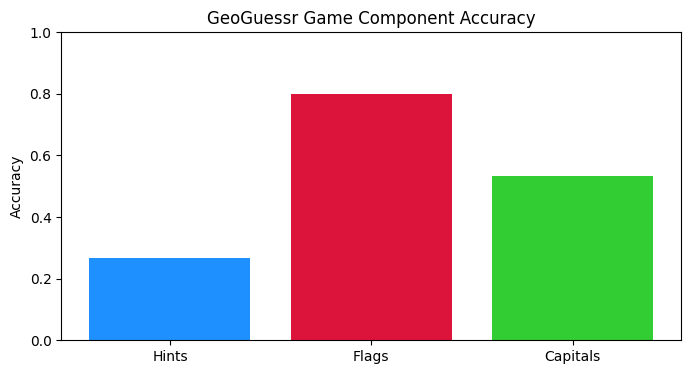


Summary: Hint Accuracy: 4/15, Flag Accuracy: 12/15, Capital Accuracy: 8/15


In [57]:
import matplotlib.pyplot as plt

def run_geoguessr_evaluation():
    print("\n=== GeoGuessr Evaluation ===")

    # 1. Hints
    hint_results = [evaluate_hint_accuracy(test) for test in hint_tests]
    n_hint = len(hint_results)
    n_hint_ok = sum([r['keywords_found'] for r in hint_results])

    print("\n--- Hint Category Test ---")
    for res in hint_results:
        print(f"Country: {res['country']} | Category: {res['category']}")
        print(f"Hint: {res['hint_text']}")
        print(f"→ Relevant Keyword Found: {'✅' if res['keywords_found'] else '❌'}\n")

    # 2. Flags
    flag_results = [evaluate_flag(test) for test in flag_tests]
    n_flag = len(flag_results)
    n_flag_ok = sum([r['correct'] for r in flag_results])

    print("\n--- Flag Test ---")
    for res in flag_results:
        print(f"Country: {res['country']}")
        print(f"Expected: {res['expected_url']}")
        print(f"Actual:   {res['actual_url']}")
        print(f"→ Correct: {'✅' if res['correct'] else '❌'}\n")

    # 3. Capitals
    capital_results = [evaluate_capital(test) for test in capital_tests]
    n_cap = len(capital_results)
    n_cap_ok = sum([r['test_result'] for r in capital_results])

    print("\n--- Capital Quiz Test ---")
    for res in capital_results:
        print(f"Country: {res['country']} | Capital: {res['capital']} | User guess: {res['user_guess']}")
        print(f"LLM Output: {res['llm_output']}")
        print(f"Test Result: {'✅' if res['test_result'] else '❌'}\n")

    from sklearn.metrics import precision_score, recall_score, accuracy_score

    # Hints
    y_true_hint = [True for _ in hint_results]
    y_pred_hint = [r['keywords_found'] for r in hint_results]

    accuracy_hint = accuracy_score(y_true_hint, y_pred_hint)
    precision_hint = precision_score(y_true_hint, y_pred_hint)
    recall_hint = recall_score(y_true_hint, y_pred_hint)

    print(f"Hint - Accuracy: {accuracy_hint:.2f}, Precision: {precision_hint:.2f}, Recall: {recall_hint:.2f}")

    # Flags
    y_true_flag = [r['expected_url'] == r['actual_url'] for r in flag_results]
    y_pred_flag = [r['correct'] for r in flag_results]

    accuracy_flag = accuracy_score(y_true_flag, y_pred_flag)
    precision_flag = precision_score(y_true_flag, y_pred_flag)
    recall_flag = recall_score(y_true_flag, y_pred_flag)

    print(f"Flag - Accuracy: {accuracy_flag:.2f}, Precision: {precision_flag:.2f}, Recall: {recall_flag:.2f}")

    # Capitals
    y_true_cap = [True for _ in capital_results]
    y_pred_cap = [r['test_result'] for r in capital_results]

    accuracy_cap = accuracy_score(y_true_cap, y_pred_cap)
    precision_cap = precision_score(y_true_cap, y_pred_cap)
    recall_cap = recall_score(y_true_cap, y_pred_cap)

    print(f"Capital - Accuracy: {accuracy_cap:.2f}, Precision: {precision_cap:.2f}, Recall: {recall_cap:.2f}")


    # --- Evaluation of Retrieval Pipelines (Baseline, Query Expansion, Re-Ranking) ---

    print("\nEvaluating Baseline Pipeline...")
    hint_baseline = get_metrics(hint_tests, dict(use_query_expansion=False, use_rerank=False))
    print("Hints Baseline:", hint_baseline)

    print("\nEvaluating Query Expansion Pipeline...")
    hint_queryexp = get_metrics(hint_tests, dict(use_query_expansion=True, use_rerank=False))
    print("Hints Query Expansion:", hint_queryexp)

    print("\nEvaluating Rerank Pipeline...")
    hint_rerank = get_metrics(hint_tests, dict(use_query_expansion=False, use_rerank=True))
    print("Hints Rerank:", hint_rerank)



    # VISUALIZE!
    categories = ['Hints', 'Flags', 'Capitals']
    accuracy = [
        n_hint_ok / n_hint if n_hint else 0,
        n_flag_ok / n_flag if n_flag else 0,
        n_cap_ok / n_cap if n_cap else 0
    ]
    plt.figure(figsize=(8, 4))
    plt.bar(categories, accuracy, color=['dodgerblue', 'crimson', 'limegreen'])
    plt.ylim(0, 1)
    plt.title("GeoGuessr Game Component Accuracy")
    plt.ylabel("Accuracy")
    plt.show()

    print(f"\nSummary: Hint Accuracy: {n_hint_ok}/{n_hint}, Flag Accuracy: {n_flag_ok}/{n_flag}, Capital Accuracy: {n_cap_ok}/{n_cap}")

run_geoguessr_evaluation()
